<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-scientific-discovery/blob/main/notebooks/lecture-05/unsupervised-learning.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

# Unsupervised learning

*Deep Learning for Scientific Discovery, Jagiellonian University. Author: Marcin Płodzień.*

So far every image came with a label, and we trained a network to predict it. Without labels only the data $\{\mathbf x_i\}_{i=1}^n$ remain, and the question is what can be learned from them: which few variables describe a sample, whether the samples form groups, and what is typical and what is unusual.

The order is that of the lecture. It begins with dimensionality reduction, the reason for projecting high-dimensional data onto a smaller space, and with its simplest, linear form: principal component analysis (PCA), computed on the MNIST handwritten digits (Modified National Institute of Standards and Technology) from the eigenvectors of the covariance matrix. The linear picture is then contrasted with t-distributed stochastic neighbour embedding (t-SNE), a non-linear map that keeps neighbours together; we write down its loss and look at the role of its perplexity. Autoencoders, neural networks that compress their input and rebuild it, come next, together with their use for anomaly detection. With k-means and DBSCAN we turn to clustering and to the scores that measure its quality. The same tools are then applied to CIFAR-10 photographs, to images of blood cells, to spin configurations of the 2D Ising model, where we look for the phase transition without labels, and finally to two tables of numbers: credit-card transactions and tumour gene expression.

Wherever a method is first computed directly with NumPy, the scikit-learn way of doing the same task follows, together with a check that both agree. All random generators are seeded, so the numbers printed below agree with the slides. Most parts run in a few minutes on a central processing unit (CPU); the deeper convolutional autoencoder of part 4 takes about 45 minutes. Most parts end with a short exercise.

Every number quoted on the slides is collected in the dictionary `nums` and saved at the end.

In [1]:
import os, sys, json, time
os.environ["CUDA_VISIBLE_DEVICES"] = ""
import numpy as np, matplotlib
import matplotlib.pyplot as plt
import torch, torch.nn as nn
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

torch.set_num_threads(4)
OUT = "figures"; os.makedirs(OUT, exist_ok=True)       # figures of the slides
RES = "results"; os.makedirs(RES, exist_ok=True)
blue, orange, navy = "#005CA7", "#EB6709", "#0A2F5C"
rng = np.random.default_rng(0); torch.manual_seed(0)
nums = {}
t0 = time.time()
def log(m): print(f"[{time.time()-t0:6.1f}s] {m}", flush=True)

def clean(ax):
    for s in ["top", "right"]: ax.spines[s].set_visible(False)

## 1. High-dimensional data

A $28\times28$ MNIST image is a vector $\mathbf x$ with 784 real components, one per pixel. We cannot look at 784 dimensions. Real images, however, are not spread over all of $\mathbb R^{784}$: pick 784 random pixel values and the result is noise, never a digit. The digits fill a thin, low-dimensional part of the space.

The analysis of such data therefore usually starts with **dimensionality reduction**, a map
$$\mathbf x\in\mathbb R^{D}\;\mapsto\;\mathbf z\in\mathbb R^{d},\qquad d\ll D, \tag{1}$$
that keeps the structure of the data. With two dimensions the points $\mathbf z_i$ can be plotted, and we can ask whether they form groups and which samples lie close to each other.

The MNIST data set ([LeCun, Bottou, Bengio and Haffner, *Proc. IEEE* **86**, 2278 (1998)](https://doi.org/10.1109/5.726791)) contains 70 000 greyscale images of handwritten digits, 60 000 for training and 10 000 for testing. One sample is a $28\times28$ array of grey levels from 0 (background) to 255 (ink), with a label from 0 to 9 giving the digit; the ten digits are roughly equally frequent. We read the original IDX files directly and scale the pixels to $[0,1]$. For the plots we use 5000 randomly chosen test images. Their labels are used only to colour the points and to score the result after a method has run; the methods themselves never see them.

In [2]:
def idx(path):
    d = open(path, "rb").read()
    if d[2] == 8 and d[3] == 3:
        n, r, c = np.frombuffer(d[4:16], ">i4"); return np.frombuffer(d[16:], np.uint8).reshape(n, r, c)
    n = np.frombuffer(d[4:8], ">i4")[0]; return np.frombuffer(d[8:], np.uint8)
from torchvision.datasets import MNIST
for train in (True, False): MNIST("data", train=train, download=True)     # downloads the four files once
R = "data/MNIST/raw/"
Xtr = idx(R + "train-images-idx3-ubyte").reshape(-1, 784) / 255.0
ytr = idx(R + "train-labels-idx1-ubyte")
Xte = idx(R + "t10k-images-idx3-ubyte").reshape(-1, 784) / 255.0
yte = idx(R + "t10k-labels-idx1-ubyte")
sel = rng.choice(len(Xte), 5000, replace=False)
X5, y5 = Xte[sel], yte[sel]
cmap = plt.get_cmap("tab10")

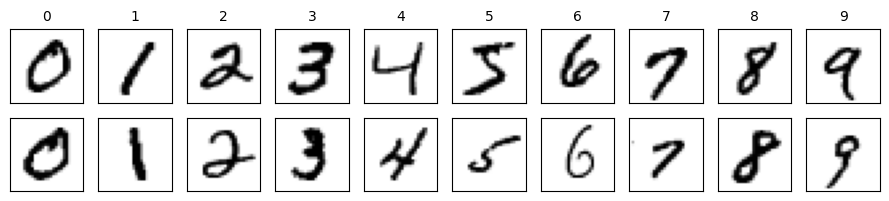

training images: (60000, 784) | test images: (10000, 784)
training images per digit: [5923 6742 5958 6131 5842 5421 5918 6265 5851 5949]


In [ ]:
# two training images of every digit, and the size of the data
fig, axs = plt.subplots(2, 10, figsize=(9, 2.2))
for dgt in range(10):
    for r, k in enumerate(np.flatnonzero(ytr == dgt)[:2]):
        axs[r, dgt].imshow(Xtr[k].reshape(28, 28), cmap="gray_r"); axs[r, dgt].set_xticks([]); axs[r, dgt].set_yticks([])
    axs[0, dgt].set_title(str(dgt), fontsize=10)
plt.tight_layout(); plt.show()
print("training images:", Xtr.shape, "| test images:", Xte.shape)
print("training images per digit:", np.bincount(ytr))


## 2. Principal component analysis

PCA is a **linear** projection. The data are $n$ samples $\mathbf x_1,\dots,\mathbf x_n$ with $D$ features each (for MNIST, 784 pixels), with the mean
$$\bar{\mathbf x}=\frac1n\sum_i\mathbf x_i , \tag{2}$$
the average image. We write $x_{ij}$ for feature $j$ (pixel $j$) of sample $i$.

How the features vary together is summarised by the **covariance matrix**, the $D\times D$ matrix
$$C_{jl}=\frac1n\sum_{i=1}^{n}(x_{ij}-\bar x_j)(x_{il}-\bar x_l),\qquad j,l=1,\dots,D . \tag{3}$$
Its diagonal entry $C_{jj}$ is the variance of pixel $j$; an off-diagonal entry $C_{jl}$ says how pixels $j$ and $l$ vary together over the data set. If each feature is first divided by its standard deviation, the same formula gives the **correlation** matrix, with ones on the diagonal. scikit-learn divides by $n-1$ instead of $n$, which rescales the eigenvalues but leaves the eigenvectors unchanged.

Because $C$ is symmetric, it has $D$ orthonormal eigenvectors $\boldsymbol\lambda_l$, unit vectors in $\mathbb R^{D}$,
$$C\boldsymbol\lambda_l=\sigma_l^2\boldsymbol\lambda_l,\qquad \sigma_1^2\ge\sigma_2^2\ge\dots\ge\sigma_D^2\ge0 , \tag{4}$$
ordered by their eigenvalues. The eigenvalue $\sigma_l^2$ is the variance of the data along the direction $\boldsymbol\lambda_l$. The $L$ eigenvectors with the largest eigenvalues are the **principal components**. The $l$-th new coordinate of sample $i$ is its projection on the $l$-th principal direction, and the $L$ projections together form the new representation $\mathbf w_i$ of $\mathbf x_i$:
$$w^{(l)}_i=\boldsymbol\lambda_l^{\top}(\mathbf x_i-\bar{\mathbf x}),\quad l=1,\dots,L,\qquad \mathbf w_i=\big[w^{(1)}_i,\dots,w^{(L)}_i\big]^{\top}=\Lambda^{\top}(\mathbf x_i-\bar{\mathbf x}), \tag{5}$$
with $\Lambda=(\boldsymbol\lambda_1,\dots,\boldsymbol\lambda_L)$ the $D\times L$ matrix of the kept eigenvectors. The map from $\mathbf x_i$ to $\mathbf w_i$ is linear and the same for every sample, so a new sample is mapped with the same $\Lambda$. Keeping the first $L$ components keeps the directions along which the data vary most, and discards those along which they hardly vary at all.

Before turning to MNIST we look at 400 correlated points in two dimensions. The figure, saved for the slides, shows the two principal axes as arrows of length twice the standard deviation along them: the first principal component (PC 1) points along the direction of largest spread, the second (PC 2) is perpendicular to it. For this cloud PC 1 carries 94.5% of the variance and PC 2 the remaining 5.5%.

In [3]:
# PCA toy: correlated 2D cloud with principal axes
pts = rng.multivariate_normal([0, 0], [[3, 1.6], [1.6, 1.2]], 400)
p2 = PCA(2).fit(pts)
fig, ax = plt.subplots(figsize=(4.2, 3.6))
ax.scatter(pts[:, 0], pts[:, 1], s=8, color=blue, alpha=0.5)
for v, l, c, name in zip(p2.components_, p2.explained_variance_, [orange, navy], ["PC 1", "PC 2"]):
    ax.annotate("", xy=2 * np.sqrt(l) * v, xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color=c, lw=2.5))
    ax.text(*(2.25 * np.sqrt(l) * v), name, color=c, fontsize=12, ha="center")
ax.set_aspect("equal"); ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); clean(ax)
plt.savefig(f"{OUT}/gen_pca_toy.png", dpi=170, bbox_inches="tight"); plt.close()
nums["pca_toy_var"] = (p2.explained_variance_ratio_).round(3).tolist()

### PCA on MNIST

For the 60 000 training images the construction above takes four operations: compute the mean image $\bar{\mathbf x}$, subtract it from every image, form the $784\times784$ covariance matrix $C$, and diagonalise it with `numpy.linalg.eigh`, which returns the eigenvalues in increasing order, so we reverse them. The figure shows the mean image, the covariance matrix, the first 100 eigenvalues divided by their sum, and the first four eigenvectors. Each eigenvector has 784 entries and can itself be shown as a $28\times28$ image, with red and blue marking positive and negative weights.

The fraction of the variance kept by the first $k$ components,
$$r_k=\frac{\sum_{a\le k}\lambda_a}{\sum_a\lambda_a}, \tag{6}$$
tells how much is lost in the projection. Two components keep 16.8% of the variance, ten keep 48.8% and fifty keep 82.5%; 87 components are needed for 90%. The eigenvalues fall quickly at first and then slowly, so a few dozen directions carry most of the variation of the digits. The last line of the output compares our projection of the 5000 test images on the first two eigenvectors with that of scikit-learn: once the arbitrary sign of each eigenvector is fixed, the two agree (largest difference 0.0 at six decimals).

In [4]:
xbar = Xtr.mean(0)                             # mean image
Xc = Xtr - xbar                                # centred data, n x 784
C = Xc.T @ Xc / len(Xc)                        # 784 x 784 covariance matrix of the pixels
lam, V = np.linalg.eigh(C)                     # C = V diag(lam) V^T, eigenvalues in increasing order
lam, V = lam[::-1], V[:, ::-1]                 # largest eigenvalues first
frac = np.cumsum(lam) / lam.sum()              # fraction of the variance kept by the first k components
nums["mnist_pca_k_for_90"] = int(np.searchsorted(frac, 0.90) + 1)
nums["mnist_pca_frac_2_10_50"] = frac[[1, 9, 49]].round(3).tolist()
print("variance kept by 2, 10, 50 components:", nums["mnist_pca_frac_2_10_50"],
      "| components needed for 90%:", nums["mnist_pca_k_for_90"])

fig = plt.figure(figsize=(12, 3.0))
gs = fig.add_gridspec(2, 8, width_ratios=[1.3, 0.25, 1.6, 0.3, 1.6, 0.25, 1, 1], wspace=0.15, hspace=0.3)
a = fig.add_subplot(gs[:, 0]); a.imshow(xbar.reshape(28, 28), cmap="gray_r"); a.set_title(r"mean image $\bar{\mathbf{x}}$", fontsize=14); a.axis("off")
a = fig.add_subplot(gs[:, 2]); v = np.abs(C).max(); a.imshow(C, cmap="RdBu_r", vmin=-v, vmax=v)
a.set_title(r"covariance $C$, $784\times784$", fontsize=14); a.set_xticks([]); a.set_yticks([])
a = fig.add_subplot(gs[:, 4]); a.semilogy(np.arange(1, 101), lam[:100] / lam.sum(), ".-", color=blue)
a.set_title(r"eigenvalues $\lambda_k/\sum_j\lambda_j$", fontsize=14); a.set_xlabel("$k$", fontsize=13); clean(a)
for j in range(4):
    a = fig.add_subplot(gs[j // 2, 6 + j % 2]); w = V[:, j]; m = np.abs(w).max()
    a.imshow(w.reshape(28, 28), cmap="RdBu_r", vmin=-m, vmax=m); a.set_title(rf"$\mathbf{{v}}_{j+1}$", fontsize=14); a.axis("off")
plt.savefig(f"{OUT}/gen_pca_mnist_steps.png", dpi=170, bbox_inches="tight"); plt.show()

# the explicit projection agrees with scikit-learn (up to the sign of each eigenvector)
Z_hand = (X5 - xbar) @ V[:, :2]
Z_skl = PCA(2).fit(Xtr).transform(X5)
print("max |difference| after fixing signs:", np.abs(np.abs(Z_hand) - np.abs(Z_skl)).max().round(6))

variance kept by 2, 10, 50 components: [0.168, 0.488, 0.825] | components needed for 90%: 87


/tmp/ipykernel_3955062/3394714064.py:22: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.savefig(f"{OUT}/gen_pca_mnist_steps.png", dpi=170, bbox_inches="tight"); plt.show()


max |difference| after fixing signs: 0.0


### PCA with scikit-learn

In practice PCA is computed with `sklearn.decomposition.PCA`. The constructor takes the number of components to keep, `n_components`, and the algorithm, `svd_solver`: `"full"` gives an exact singular value decomposition, `"randomized"` a faster approximation for large data, and the default `"auto"` chooses between them. `fit(X)` estimates the mean and the principal axes from the rows of `X`. Afterwards `mean_` holds $\bar{\mathbf x}$, `components_` holds the eigenvectors $\boldsymbol\lambda_l$ as rows, `explained_variance_` the eigenvalues and `explained_variance_ratio_` the fraction of the variance carried by each single component, the terms of equation (6). `transform(X)` returns the new coordinates $w^{(l)}_i$ of equation (5), `fit_transform(X)` does both operations at once, and `inverse_transform(Z)` maps projections back to pixel space.

scikit-learn obtains the components from the singular value decomposition of the centred data matrix rather than from the covariance matrix, and it divides by $n-1$ instead of $n$. We fit 50 components with the exact solver and compare the mean, the eigenvalues (rescaled by the ratio of these two normalisations), the explained-variance ratios, the eigenvectors and the projections of the 5000 test images with the eigendecomposition above, after fixing the sign of each eigenvector. The two routes are mathematically identical, so the agreement must be exact up to rounding, which an assertion checks. The largest differences are 0 for the mean image, $1.3\times10^{-15}$ for the eigenvalues (relative to the largest one), $1.1\times10^{-16}$ for the explained-variance ratios, $1.2\times10^{-14}$ for the eigenvectors and $2.0\times10^{-13}$ for the projections, all at the level of floating-point rounding.

In [ ]:
# PCA with scikit-learn, compared with the eigendecomposition of the covariance matrix above
pca_skl = PCA(n_components=50, svd_solver="full").fit(Xtr)
n_tr = len(Xtr)
lam_skl = pca_skl.explained_variance_ * (n_tr - 1) / n_tr                     # scikit-learn divides by n - 1
sgn = np.sign((pca_skl.components_ * V[:, :50].T).sum(1))                     # each eigenvector is defined up to its sign
dev_pca = {"mean image": np.abs(pca_skl.mean_ - xbar).max(),
           "eigenvalues / largest eigenvalue": np.abs(lam_skl - lam[:50]).max() / lam[0],
           "explained-variance ratios": np.abs(pca_skl.explained_variance_ratio_ - lam[:50] / lam.sum()).max(),
           "eigenvectors": np.abs(pca_skl.components_ * sgn[:, None] - V[:, :50].T).max(),
           "projections of the 5000 test images": np.abs(pca_skl.transform(X5) * sgn - (X5 - xbar) @ V[:, :50]).max()}
for key, val in dev_pca.items():
    print(f"max |difference|, {key}: {val:.1e}")
assert max(dev_pca.values()) < 1e-8

max |difference|, mean image: 0.0e+00
max |difference|, eigenvalues / largest eigenvalue: 1.3e-15
max |difference|, explained-variance ratios: 1.1e-16
max |difference|, eigenvectors: 1.2e-14
max |difference|, projections of the 5000 test images: 2.0e-13


### Projection on the first two components

For the plots we use scikit-learn's PCA with 50 components fitted on the training images; the first two are plotted here, and all 50 serve later as the input of t-SNE and k-means. The left panel of the figure (saved for the slides as `gen_pca_mnist.png`) shows what PCA sees, points without labels; the right panel colours the same points by the true digit. Without the colours one sees a single cloud with a dense lobe on one side. The colours show that the 1s form that lobe and the 0s spread out on the opposite side, while the other digits overlap heavily in the middle. This is expected: two components keep only 16.8% of the variance, and fifty keep 82.5%.

In [5]:
# PCA on MNIST
pca = PCA(50, random_state=0).fit(Xtr)
Z = pca.transform(X5)
nums["mnist_pca_var2"] = float(pca.explained_variance_ratio_[:2].sum())
nums["mnist_pca_var50"] = float(pca.explained_variance_ratio_.sum())
fig, axs = plt.subplots(1, 2, figsize=(9, 3.9))
axs[0].scatter(Z[:, 0], Z[:, 1], s=3, color="grey", alpha=0.5)
axs[0].set_title("what PCA sees: no labels", fontsize=14)
for d in range(10):
    m = y5 == d; axs[1].scatter(Z[m, 0], Z[m, 1], s=3, color=cmap(d), label=str(d))
axs[1].set_title("the same points, coloured by the true digit", fontsize=14)
axs[1].legend(markerscale=4, fontsize=11, ncol=2, frameon=False, loc="upper right", bbox_to_anchor=(1.28, 1))
for a in axs: a.set_xlabel("PC 1", fontsize=13); a.set_ylabel("PC 2", fontsize=13); a.set_xticks([]); a.set_yticks([]); clean(a)
plt.tight_layout(); plt.savefig(f"{OUT}/gen_pca_mnist.png", dpi=170, bbox_inches="tight"); plt.close()
log("PCA done")
print({k: round(nums[k], 3) for k in ['mnist_pca_var2', 'mnist_pca_var50']})

[  16.0s] PCA done


{'mnist_pca_var2': 0.168, 'mnist_pca_var50': 0.825}


### Three components

Adding the third principal component raises the kept variance from 16.8% to 23.0%. The figure shows the projection on the first three components from two viewing angles, so that digits overlapping in the plane may move apart along PC 3.

In [6]:
nums["mnist_pca_var3"] = float(pca.explained_variance_ratio_[:3].sum())
fig = plt.figure(figsize=(10, 4.4))
for k, (elev, azim) in enumerate([(20, 35), (20, 125)]):
    a = fig.add_subplot(1, 2, k + 1, projection="3d")
    for dgt in range(10):
        m = y5 == dgt
        a.scatter(Z[m, 0], Z[m, 1], Z[m, 2], s=2, color=cmap(dgt), label=str(dgt))
    a.view_init(elev=elev, azim=azim)
    a.set_xlabel("PC 1"); a.set_ylabel("PC 2"); a.set_zlabel("PC 3")
    a.set_xticklabels([]); a.set_yticklabels([]); a.set_zticklabels([])
a.legend(markerscale=5, fontsize=11, ncol=2, frameon=False, loc="upper left", bbox_to_anchor=(1.0, 0.95))
plt.tight_layout(); plt.savefig(f"{OUT}/gen_pca_mnist_3d.png", dpi=170, bbox_inches="tight"); plt.show()
print("variance kept by 3 components:", round(nums["mnist_pca_var3"], 3))

/tmp/ipykernel_3955062/1097729452.py:12: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout(); plt.savefig(f"{OUT}/gen_pca_mnist_3d.png", dpi=170, bbox_inches="tight"); plt.show()


variance kept by 3 components: 0.23


/tmp/ipykernel_3955062/1097729452.py:12: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.tight_layout(); plt.savefig(f"{OUT}/gen_pca_mnist_3d.png", dpi=170, bbox_inches="tight"); plt.show()


### Exercise

Plot PC 1 against PC 3, or PC 2 against PC 3. Which digits separate along which component? Look at the eigenvector images $\boldsymbol\lambda_l$: can you see why?

## 3. t-SNE

PCA keeps the directions of largest variance, but a linear projection to two dimensions squeezes curved structure together. t-distributed stochastic neighbour embedding, t-SNE (van der Maaten & Hinton, 2008), asks for something else: **points that are neighbours in $\mathbb R^{D}$ should remain neighbours in the 2D map.** To make this precise, t-SNE describes the neighbourhoods by probabilities, once in the data and once in the map, and moves the map points until the two descriptions agree.

In the data, each pair of points is reduced to one number, the squared distance
$$\lVert\mathbf x_i-\mathbf x_j\rVert^2=\sum_{k=1}^{D}(x_{ik}-x_{jk})^2 . \tag{7}$$
Around each point $\mathbf x_i$ we place a Gaussian of width $\sigma_i$ and define
$$p_{j|i}=\frac{e^{-\lVert\mathbf x_i-\mathbf x_j\rVert^2/2\sigma_i^2}}{\sum_{l\ne i}e^{-\lVert\mathbf x_i-\mathbf x_l\rVert^2/2\sigma_i^2}},\qquad p_{i|i}=0,\qquad p_{ij}=\frac{p_{j|i}+p_{i|j}}{2n}. \tag{8}$$
Here $p_{j|i}$ is a probability over the $n-1$ other points of the data set (a sum, not an integral over $\mathbb R^{D}$), and the symmetrised $p_{ij}$ sum to one over all pairs. The width $\sigma_i$ is chosen separately for every point, so that each point has about the same effective number of neighbours. This number is the **perplexity**, the main parameter of the method.

In the map, every sample $\mathbf x_i$ is represented by a point $\mathbf y_i=\big[y^{(1)}_i,y^{(2)}_i\big]^{\top}$ of the plane, its new representation. Unlike the PCA coordinates of equation (5), the $\mathbf y_i$ are not given by a formula in $\mathbf x_i$: the $2n$ numbers $y^{(a)}_i$ are the parameters of the method, found together. The similarity of the map points is measured with a Student-t distribution with one degree of freedom:
$$q_{ij}=\frac{(1+\lVert\mathbf y_i-\mathbf y_j\rVert^2)^{-1}}{\sum_{l\ne m}(1+\lVert\mathbf y_l-\mathbf y_m\rVert^2)^{-1}}. \tag{9}$$
The map points are moved by gradient descent so that $Q$ becomes close to $P$, as measured by the Kullback–Leibler (KL) divergence
$$\mathcal L=\mathrm{KL}(P\,\|\,Q)=\sum_{i\ne j}p_{ij}\log\frac{p_{ij}}{q_{ij}}. \tag{10}$$
The KL divergence punishes neighbours placed far apart ($p_{ij}$ large, $q_{ij}$ small) much more than distant points placed close together, so t-SNE preserves the local structure of the data.

The heavy-tailed Student-t in the map, instead of a second Gaussian as in the original SNE, addresses the *crowding problem*. In 784 dimensions a point can have many neighbours at similar distances; in two dimensions there is no room for all of them. The heavy tail lets moderately distant points sit far apart in the map, which opens gaps between groups. The figure below compares the two kernels. At small distances $r$ they are alike, but on a logarithmic scale the difference in the tails is plain: a similarity of 0.01 is reached at the distance 3.03 for the Gaussian and at 9.95 for the Student-t, 3.3 times farther.

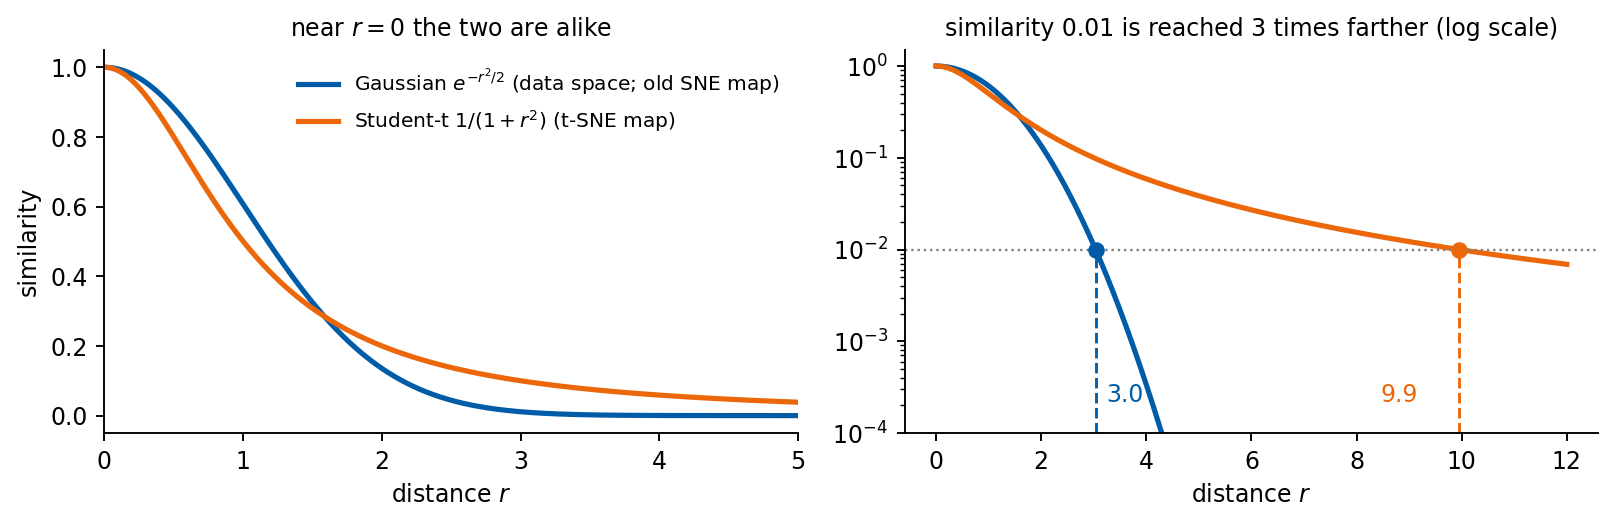

similarity 0.01: Gaussian at r = 3.03, Student-t at r = 9.95  (ratio 3.3)


In [ ]:
d = np.linspace(0, 12, 1200)
g, t = np.exp(-d**2 / 2), 1 / (1 + d**2)
level = 0.01                                                     # a small similarity: 1% of the value at r = 0
r_g, r_t = np.sqrt(2 * np.log(1 / level)), np.sqrt(1 / level - 1)
fig, axs = plt.subplots(1, 2, figsize=(9.6, 3.2))
for a in axs:
    a.plot(d, g, color=blue, lw=2.2, label=r"Gaussian $e^{-r^2/2}$ (data space; old SNE map)")
    a.plot(d, t, color=orange, lw=2.2, label=r"Student-t $1/(1+r^2)$ (t-SNE map)")
    a.set_xlabel("distance $r$"); clean(a)
axs[0].set_xlim(0, 5); axs[0].set_ylabel("similarity"); axs[0].legend(frameon=False, fontsize=8.5)
axs[0].set_title("near $r = 0$ the two are alike", fontsize=10)
axs[1].set_yscale("log"); axs[1].set_ylim(1e-4, 1.5); axs[1].axhline(level, color="grey", ls=":", lw=1)
for r_, col in [(r_g, blue), (r_t, orange)]:
    axs[1].plot([r_, r_], [1e-4, level], color=col, ls="--", lw=1.2); axs[1].plot(r_, level, "o", color=col)
axs[1].text(r_g + 0.2, 2.2e-4, f"{r_g:.1f}", color=blue, fontsize=10); axs[1].text(r_t - 1.5, 2.2e-4, f"{r_t:.1f}", color=orange, fontsize=10)
axs[1].set_title("similarity 0.01 is reached 3 times farther (log scale)", fontsize=10)
plt.tight_layout(); plt.savefig(f"{OUT}/gen_tsne_kernels.png", dpi=170, bbox_inches="tight"); plt.show()
print(f"similarity {level}: Gaussian at r = {r_g:.2f}, Student-t at r = {r_t:.2f}  (ratio {r_t / r_g:.1f})")

### t-SNE on data in 3D

A small example in three dimensions shows what t-SNE can do and PCA cannot. Eight groups of 60 points sit at the corners of a cube; each group is elongated and randomly oriented, so that the groups interpenetrate. Looking at the 3D cloud we cannot say how many groups there are, and the linear PCA projection to 2D overlaps them. t-SNE keeps neighbours together, and on its 2D map the eight groups come apart.

We use `sklearn.manifold.TSNE`. Its main parameters are the dimension of the map (`n_components`, here 2), the `perplexity`, the initialisation of the map (`init="pca"` starts from the PCA projection, which makes the result more stable than a random start) and `random_state`. The class has only `fit_transform`, which returns the map coordinates of the points it was given; there is no `transform` for new samples.

To measure the separation we run k-means with eight clusters on each 2D picture and compare the groups it finds with the true groups by the adjusted Rand index (ARI, defined in part 5; 1 for identical partitions, about 0 for random ones). The true groups are used only for this check. On the PCA projection the ARI is 0.46, on the t-SNE map 0.96. The fourth panel colours the original 3D points by the groups found on the t-SNE map.

In [ ]:
# t-SNE on cluttered 3D data: eight elongated groups at the corners of a cube, randomly oriented
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401
r3 = np.random.default_rng(3)
corners = np.array([[a, b, c] for a in (-1, 1) for b in (-1, 1) for c in (-1, 1)], float)
X3, y3 = [], []
for g, c in enumerate(corners):
    Q, _ = np.linalg.qr(r3.normal(size=(3, 3)))                                 # random orientation of the group
    X3.append(r3.normal(size=(60, 3)) * [0.7, 0.22, 0.22] @ Q.T + c); y3 += [g] * 60
X3 = np.vstack(X3); y3 = np.array(y3)
P3 = PCA(2).fit_transform(X3)                                                    # linear projection to 2D
T3 = TSNE(2, perplexity=30, init="pca", random_state=0).fit_transform(X3)        # t-SNE map to 2D
km3 = lambda F: KMeans(8, n_init=10, random_state=0).fit_predict(F)
nums["tsne3d_ari_pca"] = float(adjusted_rand_score(y3, km3(P3)))
nums["tsne3d_ari_tsne"] = float(adjusted_rand_score(y3, km3(T3)))
lab3 = km3(T3)                                                                   # groups found on the t-SNE map
fig = plt.figure(figsize=(14, 3.6))
a1 = fig.add_subplot(1, 4, 1, projection="3d"); a1.scatter(*X3.T, s=3, color="grey"); a1.view_init(18, 35)
a1.set_title("(1) 480 points in 3D, no labels", fontsize=14)
a2 = fig.add_subplot(1, 4, 2); a2.scatter(*P3.T, s=3, color="grey"); a2.set_title("(2) PCA to 2D", fontsize=14)
a3 = fig.add_subplot(1, 4, 3); a3.scatter(*T3.T, s=3, color="grey"); a3.set_title("(3) t-SNE to 2D", fontsize=14)
a4 = fig.add_subplot(1, 4, 4, projection="3d"); a4.scatter(*X3.T, s=3, c=[cmap(l) for l in lab3]); a4.view_init(18, 35)
a4.set_title("(4) 3D, coloured by the t-SNE groups", fontsize=14)
for a in [a1, a4]: a.set_xticklabels([]); a.set_yticklabels([]); a.set_zticklabels([])
for a in [a2, a3]: a.set_xticks([]); a.set_yticks([]); clean(a)
plt.tight_layout(); plt.savefig(f"{OUT}/gen_tsne_3d_cluttered.png", dpi=170, bbox_inches="tight"); plt.show()
print(f"k-means (k = 8) against the true groups, ARI: on PCA 2D {nums['tsne3d_ari_pca']:.2f}, on the t-SNE map {nums['tsne3d_ari_tsne']:.2f}")


/tmp/ipykernel_3955062/317280017.py:25: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout(); plt.savefig(f"{OUT}/gen_tsne_3d_cluttered.png", dpi=170, bbox_inches="tight"); plt.show()


k-means (k = 8) against the true groups, ARI: on PCA 2D 0.46, on the t-SNE map 0.96


/tmp/ipykernel_3955062/317280017.py:25: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.tight_layout(); plt.savefig(f"{OUT}/gen_tsne_3d_cluttered.png", dpi=170, bbox_inches="tight"); plt.show()


### t-SNE on MNIST

As is common, we run t-SNE not on the 784 pixels but on the 50 PCA components of the 5000 test digits: this is faster, and the noise carried by the last components is removed. The figure is saved for the slides (`gen_tsne_mnist.png`) and not displayed here; like the PCA figure, it shows the map without labels and coloured by the true digit, with each digit written at the median of its points.

In [8]:
# t-SNE on MNIST (on 50 PCA components)
E = TSNE(2, perplexity=30, init="pca", random_state=0).fit_transform(Z)
fig, axs = plt.subplots(1, 2, figsize=(9, 3.9))
axs[0].scatter(E[:, 0], E[:, 1], s=3, color="grey", alpha=0.5)
axs[0].set_title("what t-SNE sees: no labels", fontsize=11)
for d in range(10):
    m = y5 == d; axs[1].scatter(E[m, 0], E[m, 1], s=3, color=cmap(d), label=str(d))
    axs[1].text(*np.median(E[m], 0), str(d), fontsize=13, weight="bold", ha="center", va="center")
axs[1].set_title("the same points, coloured by the true digit", fontsize=11)
for a in axs: a.set_xticks([]); a.set_yticks([]); a.set_xlabel("t-SNE 1"); a.set_ylabel("t-SNE 2"); clean(a)
plt.tight_layout(); plt.savefig(f"{OUT}/gen_tsne_mnist.png", dpi=170, bbox_inches="tight"); plt.close()
log("t-SNE done")

[  34.0s] t-SNE done


### t-SNE in three dimensions

The map can also be three-dimensional: the loss is the same, with three-dimensional map points $\mathbf y_i$. The figure shows one map from two viewing angles.

/tmp/ipykernel_3617519/3624932943.py:10: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout(); plt.savefig(f"{OUT}/gen_tsne_mnist_3d.png", dpi=170, bbox_inches="tight"); plt.show()


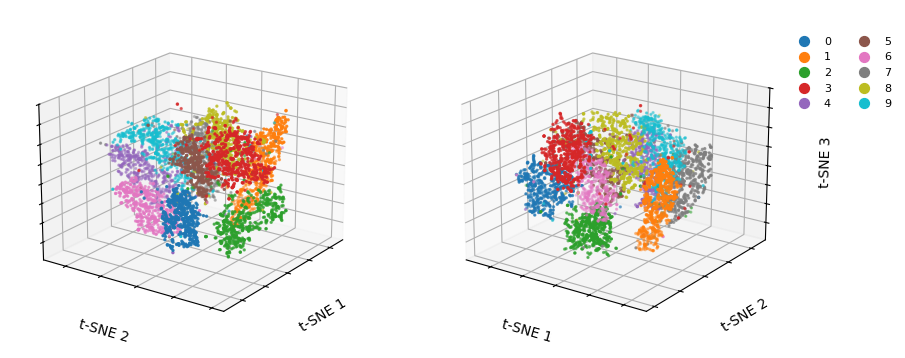

In [9]:
E3 = TSNE(3, perplexity=30, init="pca", random_state=0).fit_transform(Z)
fig = plt.figure(figsize=(10, 4.4))
for kk, (elev, azim) in enumerate([(20, 35), (20, 125)]):
    a = fig.add_subplot(1, 2, kk + 1, projection="3d")
    for dgt in range(10):
        m = y5 == dgt; a.scatter(E3[m, 0], E3[m, 1], E3[m, 2], s=2, color=cmap(dgt), label=str(dgt))
    a.view_init(elev=elev, azim=azim); a.set_xticklabels([]); a.set_yticklabels([]); a.set_zticklabels([])
    a.set_xlabel("t-SNE 1"); a.set_ylabel("t-SNE 2"); a.set_zlabel("t-SNE 3")
a.legend(markerscale=5, fontsize=8, ncol=2, frameon=False, loc="upper left", bbox_to_anchor=(1.0, 0.95))
plt.tight_layout(); plt.savefig(f"{OUT}/gen_tsne_mnist_3d.png", dpi=170, bbox_inches="tight"); plt.show()

### Perplexity

The perplexity sets how many neighbours each point takes into account. We run t-SNE on the first 2000 of the same test digits with perplexities 5, 30 and 100; 30 is the default of scikit-learn. With perplexity 5 only the closest neighbours count, and the digits form loose, ragged groups broken into strands. With larger perplexity the map is smoother, and at 100 most digits form compact, well-separated islands, while the 4s, 7s and 9s remain close together at every setting.

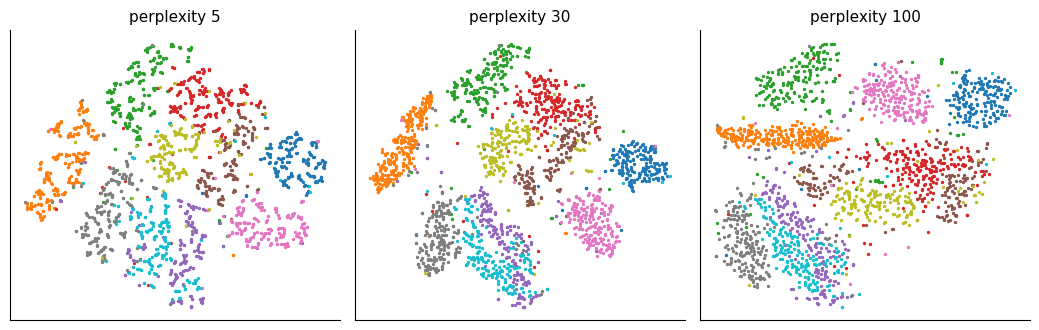

In [10]:
Zs, ys = Z[:2000], y5[:2000]                  # first 2000 of the same test digits (no new random numbers)
fig, axs = plt.subplots(1, 3, figsize=(10.5, 3.4))
for a, pp in zip(axs, [5, 30, 100]):
    Ep = TSNE(2, perplexity=pp, init="pca", random_state=0).fit_transform(Zs)
    for dgt in range(10):
        m = ys == dgt; a.scatter(Ep[m, 0], Ep[m, 1], s=2, color=cmap(dgt))
    a.set_title(f"perplexity {pp}", fontsize=11); a.set_xticks([]); a.set_yticks([]); clean(a)
plt.tight_layout(); plt.savefig(f"{OUT}/gen_tsne_perplexity.png", dpi=170, bbox_inches="tight"); plt.show()

### t-SNE map

A t-SNE map is easy to over-interpret, and the loss tells which of its features carry meaning. The position of a cluster carries none: the loss depends only on distances between map points, so a rotated, mirrored or shifted map is equally good, and another random seed puts the clusters elsewhere. The separation between clusters carries little meaning, because pairs of distant points have almost vanishing $p_{ij}$ and barely enter the loss, while the Student-t tail pushes groups apart; a wide gap does not mean very different data. Cluster sizes carry little meaning either, since $\sigma_i$ adapts to the local density and dense and sparse groups come out of similar size. Even distances inside a cluster are not to scale: only the nearest neighbours of each point, about as many as the perplexity, are kept, and larger distances are not.

What the map shows reliably is which points are close neighbours.

### Exercise

Rerun t-SNE with another `random_state`. Which features of the map stay, which change?

## 4. Autoencoders

PCA and t-SNE are fixed procedures. An autoencoder learns the compression instead, and it consists of two neural networks trained together. The **encoder** has $D$ inputs (the size of the data, 784 pixels), $d$ outputs (the size of the latent space, chosen by us) and its own parameters (weights and biases) $\boldsymbol\theta_E$; it maps an input to the *latent* vector
$$E_{\boldsymbol\theta_E}:\mathbb R^{D}\to\mathbb R^{d},\qquad \mathbf z=E_{\boldsymbol\theta_E}(\mathbf x). \tag{11}$$
The **decoder** has $d$ inputs, $D$ outputs and its own parameters $\boldsymbol\theta_D$; it maps the latent vector back to the reconstruction
$$G_{\boldsymbol\theta_D}:\mathbb R^{d}\to\mathbb R^{D},\qquad \hat{\mathbf x}=G_{\boldsymbol\theta_D}(\mathbf z). \tag{12}$$

Training needs a loss function: one number that measures how badly the networks do on the training data for given values of their parameters. Training means finding the parameters that make it smallest. Without labels every input is its own target, and the loss compares each input with its reconstruction
$$\hat{\mathbf x}_i=G_{\boldsymbol\theta_D}\big(E_{\boldsymbol\theta_E}(\mathbf x_i)\big) \tag{13}$$
pixel by pixel:
$$\mathcal L(\boldsymbol\theta_E,\boldsymbol\theta_D)=\frac1n\sum_{i=1}^{n}\frac1D\sum_{j=1}^{D}(x_{ij}-\hat x_{ij})^2 . \tag{14}$$
The parameters $\boldsymbol\theta_E$ and $\boldsymbol\theta_D$ are updated together by gradient descent and backpropagation.

The point of the construction is the bottleneck, a latent size $d$ much smaller than $D$. It forces the encoder to extract the features of the data that the decoder needs to rebuild the input, and to encode them in $\mathbf z$. After training, the encoder compresses an image to $d$ numbers (with sixteen latent numbers, 49 times fewer than pixels), and the decoder rebuilds the image from them.

The space of the latent vectors, the **latent space**, is a learned, compressed description of the data. The loss does not ask for any particular structure in it, but similar inputs tend to get nearby latent vectors, because the decoder must rebuild them alike. The latent space can therefore be analysed like any data set, with PCA or t-SNE on the latent vectors and with a search for clusters. A linear autoencoder trained with this loss finds the same subspace as PCA; with non-linear layers it can follow curved structure.

Our autoencoder has dense layers $784\to256\to64\to d$ and back, rectified linear unit (ReLU) activations, a sigmoid at the output (pixels lie in $[0,1]$), and is trained with the Adam optimiser for 15 epochs. We first take two latent numbers, so that the latent space can be plotted, and then sixteen. On the 5000 test images the mean squared error (MSE) per pixel is 0.0404 with two latent numbers and 0.0134 with sixteen. The plot of the 2D latent space and the reconstructions are saved for the slides.

### Autoencoder architecture

Three views of a network are useful, and each answers a different question. A drawing of the layers as columns of neurons shows the shape of the computation, here the narrowing towards the bottleneck and the widening back. A layer table lists every layer with the shape of its output and its number of parameters; it is what one consults when shapes do not match or when the size of a model matters. A graph of the forward pass shows how tensors flow between modules, including nested blocks and branches that a table flattens away. The first view is produced by our own function `draw_network`, the other two by the packages `torchinfo` and `torchview`.

`draw_network` draws a fully connected network as columns of circles, one column per layer, with a thin grey line for every connection between neighbouring columns. Its argument `layer_sizes` lists the layer widths from input to output; an entry may also be a list of widths, which stacks several blocks in one column, as for the mean and log-variance of a variational autoencoder or for an image together with a one-hot condition. `labels` names the columns (the true size is always shown underneath), `colors` sets the fill colour per column or per block, and `groups` puts a bracket with a name above a range of columns. We colour the data grey, hidden layers blue, the latent layer orange and conditioning inputs green. A layer wider than `max_nodes` (10 by default) is drawn as its first and last few neurons with a vertical ellipsis in between, and the height of every block grows logarithmically with its width $s$,
$$h(s)=h_{\min}+c\log_{10}s, \tag{15}$$
so that the bottleneck remains visible although all wide layers are truncated to the same number of circles. A network of one's own is drawn by passing its widths, e.g. `draw_network([784, 128, 10])` for a classifier with one hidden layer; the function returns the matplotlib axes, from which the figure can be saved.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

# Colours used for the network drawings: grey for the data (input and output),
# blue for hidden layers, orange for the latent (bottleneck) layer and green
# for an extra conditioning input such as a one-hot class label.
GREY, BLUE, ORANGE, GREEN = "#8C8C8C", "#005CA7", "#EB6709", "#2E8B57"


def draw_network(layer_sizes, labels=None, colors=None, max_nodes=10,
                 groups=None, no_input=None, ax=None, node_radius=0.11,
                 x_gap=1.6, min_height=1.0, height_scale=1.1, fontsize=13):
    """Draw a fully connected network as columns of circles joined by edges.

    Parameters
    ----------
    layer_sizes : list
        One entry per column, from the input to the output. An entry is
        either an int (the number of neurons of one layer) or a list of ints
        (several blocks stacked in the same column, e.g. [16, 16] for the mean
        and the log-variance of a variational autoencoder, or [784, 10] for an
        image together with a one-hot condition).
    labels : list, optional
        Names shown under each column next to the true layer size. An entry
        may be None (size only), a string, or, for a stacked column, a list
        with one string per block.
    colors : list, optional
        Fill colour of the nodes of each column (or a list with one colour per
        block). By default the first and the last column are grey and all
        others blue.
    max_nodes : int
        Largest number of circles drawn for one block. A larger block is shown
        by its first and last few nodes with a vertical ellipsis in between;
        the true size is always shown in the label.
    groups : list of (text, first_column, last_column), optional
        Brackets drawn above a range of columns, e.g. ("encoder", 0, 2).
    no_input : list of (column, block), optional
        Blocks that receive no edges from the previous column, e.g. a condition
        c that enters the decoder from outside.
    ax : matplotlib Axes, optional
        Axes to draw into; a new figure is created when None.
    node_radius, x_gap : float
        Radius of a circle and horizontal distance between columns.
    min_height, height_scale : float
        The height of a block of size s is min_height + height_scale*log10(s),
        so that a narrow layer is visibly shorter than a wide one.
    fontsize : int
        Font size of all labels.

    Returns
    -------
    ax : the matplotlib Axes with the drawing.
    """
    n = len(layer_sizes)
    # Turn every entry into a list of blocks, so that a plain layer is a
    # column with a single block.
    blocks = [s if isinstance(s, (list, tuple)) else [s] for s in layer_sizes]
    if labels is None:
        labels = [None] * n
    if colors is None:
        colors = [GREY] + [BLUE] * (n - 2) + [GREY]
    no_input = set(no_input or [])

    def per_block(value, k):
        # Repeat a single value for all k blocks of a column, or keep a list.
        return list(value) if isinstance(value, (list, tuple)) else [value] * k

    if ax is None:
        _, ax = plt.subplots(figsize=(1.9 * n + 1, 5.5))

    # ---- Node positions ---------------------------------------------------
    # Column i sits at x = i * x_gap. Inside a column the blocks are stacked
    # from top to bottom with a small gap, and the whole column is centred
    # on y = 0. Each block gets a height that grows with log10 of its size
    # (but is never too small for its circles to fit without overlapping);
    # the drawn nodes are spread evenly over that height.
    nodes = []            # nodes[i][b] = list of (x, y) of block b in column i
    tops, bottoms = [], []
    gap = 0.9             # vertical space between stacked blocks (holds a label)
    for i, blk in enumerate(blocks):
        cols = per_block(colors[i], len(blk))
        labs = per_block(labels[i], len(blk))
        heights = [max(min_height + height_scale * np.log10(s),
                       (min(s, max_nodes) - 1) * 2.3 * node_radius) for s in blk]
        total = sum(heights) + gap * (len(blk) - 1)
        x, y_top = i * x_gap, total / 2
        column = []
        for s, h, c, lab in zip(blk, heights, cols, labs):
            shown = min(s, max_nodes)
            if s <= max_nodes:
                # Small block: draw every neuron.
                ys = np.linspace(y_top, y_top - h, shown) if shown > 1 else np.array([y_top - h / 2])
            else:
                # ---- Truncation of large layers ----------------------------
                # Draw max_nodes circles: half in the upper 38 % of the block,
                # half in the lower 38 %, and a vertical ellipsis in the
                # middle to show that neurons are omitted.
                k = max_nodes // 2
                ys = np.concatenate([np.linspace(y_top, y_top - 0.38 * h, k),
                                     np.linspace(y_top - 0.62 * h, y_top - h, max_nodes - k)])
                ax.text(x, y_top - 0.5 * h, r"$\vdots$", ha="center", va="center",
                        fontsize=fontsize + 6, color=c, zorder=4)
            for y in ys:
                ax.add_patch(Circle((x, y), node_radius, facecolor=c,
                                    edgecolor="black", lw=0.6, zorder=3))
            column.append([(x, y) for y in ys])

            # ---- Labels of stacked blocks ----------------------------------
            # In a column with several blocks each block is labelled just
            # below its last node, in its own colour, on a white box so that
            # the edges behind do not hide the text.
            if len(blk) > 1:
                text = f"{s}" if lab is None else f"{lab} {s}"
                ax.text(x, y_top - h - 0.2, text, ha="center", va="top",
                        fontsize=fontsize - 1, color=c, zorder=5,
                        bbox=dict(facecolor="white", edgecolor="none", pad=0.5))
            y_top -= h + gap

        # ---- Label of a single-block column: name and true size below ----
        if len(blk) == 1:
            lab = labs[0]
            text = f"{blk[0]}" if lab is None else f"{lab}\n{blk[0]}"
            ax.text(x, -total / 2 - 0.3, text, ha="center", va="top", fontsize=fontsize)
        nodes.append(column)
        tops.append(total / 2)
        bottoms.append(-total / 2)

    # ---- Edges ---------------------------------------------------------------
    # A dense layer connects every neuron of one column with every neuron of
    # the next, so we draw a thin grey line for every pair of drawn nodes,
    # skipping the blocks listed in no_input. zorder=1 keeps lines behind
    # the circles.
    for i in range(n - 1):
        sources = [p for block in nodes[i] for p in block]
        for b, block in enumerate(nodes[i + 1]):
            if (i + 1, b) in no_input:
                continue
            for (x0, y0) in sources:
                for (x1, y1) in block:
                    ax.plot([x0, x1], [y0, y1], color="#B0B0B0", lw=0.35, zorder=1)

    # ---- Group brackets ------------------------------------------------------
    # A bracket above columns first..last with its text, e.g. "encoder".
    y_br = max(tops) + 0.45
    for text, i0, i1 in (groups or []):
        x0, x1 = i0 * x_gap - 0.3, i1 * x_gap + 0.3
        ax.plot([x0, x0, x1, x1], [y_br - 0.12, y_br, y_br, y_br - 0.12],
                color="black", lw=1.2)
        ax.text((x0 + x1) / 2, y_br + 0.1, text, ha="center", va="bottom",
                fontsize=fontsize)

    # ---- Axes limits ----------------------------------------------------------
    # Leave room for the brackets above and the labels below.
    ax.set_xlim(-0.8, (n - 1) * x_gap + 0.8)
    ax.set_ylim(min(bottoms) - 1.3, y_br + (0.7 if groups else 0.2))
    ax.set_aspect("equal")
    ax.axis("off")
    return ax


The dense autoencoder with sixteen latent numbers, which serves for the reconstructions, the latent-space analysis and the anomaly scores, compresses 784 pixels into 16 numbers and expands them back; the model with two latent numbers differs only in the orange column. The model is built exactly as in `train_ae` but not trained. Its widths are not typed into the drawing: they are read from the model itself, the input width of the first `nn.Linear` layer and the output width of every `nn.Linear` layer, so that the picture cannot disagree with the code. The drawing is also saved for the slides as `arch_ae_dense.png`, at the size at which it appears there; at most seven neurons are drawn per layer, and the true width is written under each column.

layer widths read from the model: [784, 256, 64, 16, 64, 256, 784]


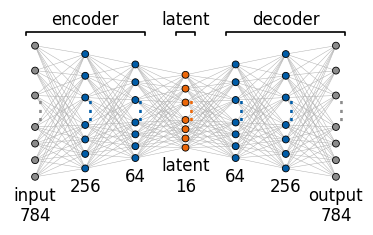

In [ ]:
# the dense autoencoder with d = 16 latent numbers, built exactly as in train_ae but not trained;
# creating the layers draws random weights, so the global random generator is restored afterwards
d_latent = 16
with torch.random.fork_rng(devices=[]):
    ae_dense = nn.Sequential(
        nn.Sequential(nn.Linear(784, 256), nn.ReLU(), nn.Linear(256, 64), nn.ReLU(), nn.Linear(64, d_latent)),                # encoder
        nn.Sequential(nn.Linear(d_latent, 64), nn.ReLU(), nn.Linear(64, 256), nn.ReLU(), nn.Linear(256, 784), nn.Sigmoid()))  # decoder

# layer widths read from the model: the input width of the first Linear layer, then the output width of every Linear layer
linears = [m for m in ae_dense.modules() if isinstance(m, nn.Linear)]
sizes = [linears[0].in_features] + [m.out_features for m in linears]
n_enc = sum(isinstance(m, nn.Linear) for m in ae_dense[0])     # Linear layers of the encoder; the last one ends in the latent layer
n_dec = len(sizes) - n_enc - 2                                 # hidden layers of the decoder
print("layer widths read from the model:", sizes)

# final slide size (about 0.9 of the width of a 16:9 slide), so that the 12 pt labels stay at least 11 pt on the slide
fig, ax = plt.subplots(figsize=(5.2, 2.7))
draw_network(sizes,
             labels=["input"] + [None] * (n_enc - 1) + ["latent"] + [None] * n_dec + ["output"],
             colors=[GREY] + [BLUE] * (n_enc - 1) + [ORANGE] + [BLUE] * n_dec + [GREY],
             groups=[("encoder", 0, n_enc - 1), ("latent", n_enc, n_enc), ("decoder", n_enc + 1, len(sizes) - 1)],
             max_nodes=7, fontsize=12, ax=ax)
fig.savefig(f"{OUT}/arch_ae_dense.png", dpi=200, bbox_inches="tight", facecolor="white")
plt.show()


`torchinfo.summary(model, input_size=(1, 784))` passes one dummy input of the given shape through the model and prints every layer with its output shape and parameter count, followed by the totals and an estimate of the memory needed. Creating a layer draws its initial weights from PyTorch's random generator, and the dummy input of `summary` is random too, so both happen inside `torch.random.fork_rng`, which restores the generator afterwards; the autoencoders trained later are unaffected. An assertion compares the number of weights and biases between the drawn columns with the total of the table, so the drawing and the table are checked to describe the same network.

A dense layer from $m$ to $k$ neurons has $mk$ weights and $k$ biases. The first layer alone, from 784 to 256 neurons, has
$$784\cdot256+256=200\,960 \tag{16}$$
parameters, and the last one, from 256 back to 784, has 201 488; together they hold 92% of the 437 664 parameters of the network, while the bottleneck layers are cheap.

In [ ]:
# layer table of the same model with torchinfo; its dummy input is random, so the generator is restored afterwards
from torchinfo import summary
with torch.random.fork_rng(devices=[]):
    info_dense = summary(ae_dense, input_size=(1, sizes[0]), verbose=0)
print(info_dense)

# the drawing and the table describe the same network: weights and biases between the drawn columns add up to the torchinfo total
n_drawn = sum(m * k + k for m, k in zip(sizes[:-1], sizes[1:]))
assert n_drawn == info_dense.total_params, (n_drawn, info_dense.total_params)
print(f"parameters from the drawn widths: {n_drawn:,} = torchinfo total: {info_dense.total_params:,}")


Layer (type:depth-idx)                   Output Shape              Param #
Sequential                               [1, 784]                  --
├─Sequential: 1-1                        [1, 16]                   --
│    └─Linear: 2-1                       [1, 256]                  200,960
│    └─ReLU: 2-2                         [1, 256]                  --
│    └─Linear: 2-3                       [1, 64]                   16,448
│    └─ReLU: 2-4                         [1, 64]                   --
│    └─Linear: 2-5                       [1, 16]                   1,040
├─Sequential: 1-2                        [1, 784]                  --
│    └─Linear: 2-6                       [1, 64]                   1,088
│    └─ReLU: 2-7                         [1, 64]                   --
│    └─Linear: 2-8                       [1, 256]                  16,640
│    └─ReLU: 2-9                         [1, 256]                  --
│    └─Linear: 2-10                      [1, 784]                 

In [11]:
# Autoencoder on MNIST
def train_ae(latent, X, epochs, lr=1e-3):
    enc = nn.Sequential(nn.Linear(784, 256), nn.ReLU(), nn.Linear(256, 64), nn.ReLU(), nn.Linear(64, latent))
    dec = nn.Sequential(nn.Linear(latent, 64), nn.ReLU(), nn.Linear(64, 256), nn.ReLU(), nn.Linear(256, 784), nn.Sigmoid())
    opt = torch.optim.Adam(list(enc.parameters()) + list(dec.parameters()), lr=lr)
    Xt = torch.tensor(X, dtype=torch.float32)
    for ep in range(epochs):
        perm = torch.randperm(len(Xt))
        for i in range(0, len(Xt), 256):
            b = Xt[perm[i:i + 256]]
            loss = ((dec(enc(b)) - b) ** 2).mean()
            opt.zero_grad(); loss.backward(); opt.step()
    return enc, dec
Xtr_t = torch.tensor(Xtr, dtype=torch.float32); X5_t = torch.tensor(X5, dtype=torch.float32)
enc2, dec2 = train_ae(2, Xtr, 15)
with torch.no_grad():
    L2 = enc2(X5_t).numpy(); nums["ae2_test_mse"] = float(((dec2(enc2(X5_t)) - X5_t) ** 2).mean())
fig, ax = plt.subplots(figsize=(4.6, 3.9))
for d in range(10):
    m = y5 == d; ax.scatter(L2[m, 0], L2[m, 1], s=3, color=cmap(d), label=str(d))
ax.legend(markerscale=4, fontsize=8, ncol=2, frameon=False, loc="upper right", bbox_to_anchor=(1.3, 1))
ax.set_xlabel("latent $z_1$"); ax.set_ylabel("latent $z_2$"); ax.set_title("2D latent space, coloured by the true digit", fontsize=10); clean(ax)
plt.savefig(f"{OUT}/gen_ae_latent_mnist.png", dpi=170, bbox_inches="tight"); plt.close()
log("AE latent 2 done")
enc16, dec16 = train_ae(16, Xtr, 15)
with torch.no_grad():
    show = X5_t[:8]; r2 = dec2(enc2(show)).numpy(); r16 = dec16(enc16(show)).numpy()
    nums["ae16_test_mse"] = float(((dec16(enc16(X5_t)) - X5_t) ** 2).mean())
fig, axs = plt.subplots(3, 8, figsize=(8, 3.2))
for j in range(8):
    for i, (img, lab) in enumerate([(show[j].numpy(), "input"), (r16[j], "latent 16"), (r2[j], "latent 2")]):
        axs[i, j].imshow(img.reshape(28, 28), cmap="gray_r"); axs[i, j].set_xticks([]); axs[i, j].set_yticks([])
        if j == 0: axs[i, j].set_ylabel(lab, fontsize=10)
plt.savefig(f"{OUT}/gen_ae_reconstructions.png", dpi=170, bbox_inches="tight"); plt.close()
log("AE latent 16 done")
print({k: round(nums[k], 4) for k in ['ae2_test_mse', 'ae16_test_mse']})

[ 174.7s] AE latent 2 done


[ 206.6s] AE latent 16 done


{'ae2_test_mse': 0.0404, 'ae16_test_mse': 0.0134}


For the autoencoder diagram on the slides we pick a clearly written test digit, the 3 that the autoencoder with sixteen latent numbers rebuilds best (index 4495 among the 5000 test images, reconstruction error 0.0052), and show the input, its 16 latent numbers and its reconstruction.

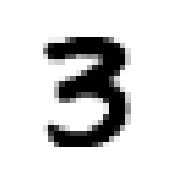

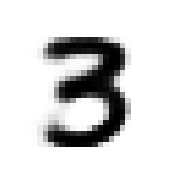

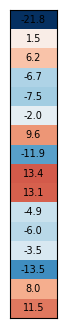

test digit index 4495 | reconstruction error 0.0052 | latent vector: [-21.81   1.51   6.19  -6.72  -7.54  -2.01   9.62 -11.93  13.37  13.1
  -4.93  -5.97  -3.52 -13.47   8.    11.5 ]


In [12]:
with torch.no_grad():
    rec_err = ((dec16(enc16(X5_t)) - X5_t) ** 2).mean(1).numpy()
threes = np.flatnonzero(y5 == 3)
k3 = threes[np.argmin(rec_err[threes])]                     # the 3 with the smallest reconstruction error
with torch.no_grad():
    z3 = enc16(X5_t[k3:k3 + 1])[0].numpy(); x_out = dec16(enc16(X5_t[k3:k3 + 1]))[0].numpy()
for arr, name in [(X5[k3], "gen_ae_in.png"), (x_out, "gen_ae_out.png")]:
    plt.figure(figsize=(2, 2)); plt.imshow(arr.reshape(28, 28), cmap="gray_r"); plt.axis("off")
    plt.savefig(f"{OUT}/{name}", dpi=170, bbox_inches="tight", pad_inches=0.02); plt.show()
fig, ax = plt.subplots(figsize=(0.6, 4.0))
ax.imshow(z3[:, None], cmap="RdBu_r", vmin=-np.abs(z3).max(), vmax=np.abs(z3).max(), aspect="auto")
for i_, v in enumerate(z3): ax.text(0, i_, f"{v:.1f}", ha="center", va="center", fontsize=7)
ax.set_xticks([]); ax.set_yticks([])
plt.savefig(f"{OUT}/gen_ae_z.png", dpi=170, bbox_inches="tight", pad_inches=0.02); plt.show()
print("test digit index", k3, "| reconstruction error", round(float(rec_err[k3]), 4), "| latent vector:", z3.round(2))

### The loss per pixel

The loss of equation (14) compares the input with its reconstruction **pixel by pixel**, with $i$ the image and $j$ the pixel. It is zero only if every pixel is rebuilt exactly. The map of squared differences shows where the reconstruction of our digit is imperfect: the errors sit along the edges of the strokes. The mean of the map is the loss of this one image, 0.0052.

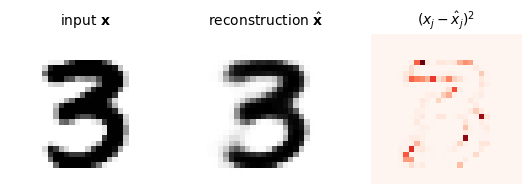

mean of the error map (the loss of this image): 0.0052


In [13]:
err_map = (X5[k3] - x_out) ** 2
fig, axs = plt.subplots(1, 3, figsize=(6.6, 2.3))
for a, im, t, cm in zip(axs, [X5[k3], x_out, err_map], [r"input $\mathbf{x}$", r"reconstruction $\hat{\mathbf{x}}$", r"$(x_j - \hat{x}_j)^2$"], ["gray_r", "gray_r", "Reds"]):
    a.imshow(im.reshape(28, 28), cmap=cm); a.set_title(t, fontsize=10); a.axis("off")
plt.savefig(f"{OUT}/gen_ae_loss_map.png", dpi=170, bbox_inches="tight"); plt.show()
print("mean of the error map (the loss of this image):", round(float(err_map.mean()), 4))

### A convolutional autoencoder

The autoencoder above is made of dense layers: it sees an image as a flat list of 784 numbers. A **convolutional** encoder uses the 2D structure of the image, like the convolutional neural networks (CNNs) of Lecture 4. Ours has two convolutions with stride 2 ($28\to14\to7$ pixels, 32 and 64 channels), followed by a dense layer to two latent numbers; the decoder mirrors it with transposed convolutions. It is trained with its own random seed, and the generator is restored afterwards, so the later results do not change.

The figure compares its 2D latent space with that of the dense autoencoder. The two reconstruct equally well (test MSE 0.039 and 0.040), but the digits are better separated in the convolutional latent space: k-means with ten clusters on it matches the digits with ARI 0.269, against 0.197 for the dense autoencoder. Training took 169 s.

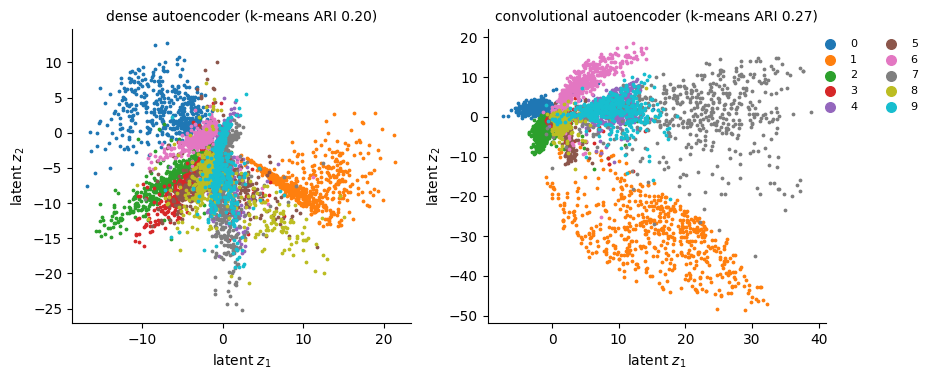

trained in 169 s; {'ae2_latent_kmeans_ari': 0.197, 'cae2_latent_kmeans_ari': 0.269, 'ae2_test_mse': 0.04, 'cae2_test_mse': 0.039}


In [14]:
class ConvAE(nn.Module):
    def __init__(self, d=2):
        super().__init__()
        self.enc = nn.Sequential(nn.Conv2d(1, 32, 3, 2, 1), nn.ReLU(), nn.Conv2d(32, 64, 3, 2, 1), nn.ReLU(),
                                 nn.Flatten(), nn.Linear(64 * 7 * 7, 128), nn.ReLU(), nn.Linear(128, d))
        self.dec = nn.Sequential(nn.Linear(d, 128), nn.ReLU(), nn.Linear(128, 64 * 7 * 7), nn.ReLU(), nn.Unflatten(1, (64, 7, 7)),
                                 nn.ConvTranspose2d(64, 32, 3, 2, 1, output_padding=1), nn.ReLU(),
                                 nn.ConvTranspose2d(32, 1, 3, 2, 1, output_padding=1), nn.Sigmoid())
    def forward(self, x): return self.dec(self.enc(x))
state = torch.get_rng_state(); torch.manual_seed(3)
cae = ConvAE(2); optc = torch.optim.Adam(cae.parameters(), 1e-3)
Xtr_img = Xtr_t.reshape(-1, 1, 28, 28); t0c = time.time()
for ep in range(15):
    perm = torch.randperm(len(Xtr_img))
    for i in range(0, len(perm), 256):
        b = Xtr_img[perm[i:i + 256]]; loss = ((cae(b) - b) ** 2).mean(); optc.zero_grad(); loss.backward(); optc.step()
torch.set_rng_state(state)
with torch.no_grad():
    Lc = cae.enc(X5_t.reshape(-1, 1, 28, 28)).numpy()
    nums["cae2_test_mse"] = float(((cae(X5_t.reshape(-1, 1, 28, 28)) - X5_t.reshape(-1, 1, 28, 28)) ** 2).mean())
nums["ae2_latent_kmeans_ari"] = float(adjusted_rand_score(y5, KMeans(10, n_init=10, random_state=0).fit(L2).labels_))
nums["cae2_latent_kmeans_ari"] = float(adjusted_rand_score(y5, KMeans(10, n_init=10, random_state=0).fit(Lc).labels_))
fig, axs = plt.subplots(1, 2, figsize=(9.4, 3.9))
for a, P2, t in zip(axs, [L2, Lc], [f"dense autoencoder (k-means ARI {nums['ae2_latent_kmeans_ari']:.2f})", f"convolutional autoencoder (k-means ARI {nums['cae2_latent_kmeans_ari']:.2f})"]):
    for dgt in range(10):
        m = y5 == dgt; a.scatter(P2[m, 0], P2[m, 1], s=3, color=cmap(dgt), label=str(dgt))
    a.set_title(t, fontsize=10); a.set_xlabel("latent $z_1$"); a.set_ylabel("latent $z_2$"); clean(a)
axs[1].legend(markerscale=4, fontsize=8, ncol=2, frameon=False, loc="upper right", bbox_to_anchor=(1.3, 1))
plt.tight_layout(); plt.savefig(f"{OUT}/gen_ae_dense_vs_conv.png", dpi=170, bbox_inches="tight"); plt.show()
print(f"trained in {time.time() - t0c:.0f} s;", {k: round(nums[k], 3) for k in ["ae2_latent_kmeans_ari", "cae2_latent_kmeans_ari", "ae2_test_mse", "cae2_test_mse"]})

### Convolutional autoencoder architecture

A convolutional network is not a stack of fully connected columns, and `draw_network` does not describe it; its layers are characterised by the shapes of the tensors passing through them. For the convolutional autoencoder with two latent numbers, `summary(ConvAE(2), input_size=(1, 1, 28, 28))` lists every convolution with its output shape (batch, channels, height, width) and its parameters. A $3\times3$ convolution from $c_{\rm in}$ to $c_{\rm out}$ channels has
$$n_{\rm par}=9\,c_{\rm in}c_{\rm out}+c_{\rm out} \tag{17}$$
parameters (weights and biases), independent of the image size, so the two convolutions of the encoder have only 18 816 parameters; 95% of the 844 291 parameters sit in the two dense layers that connect the $64\times7\times7$ feature maps with the 128-dimensional layer next to the latent vector.

`torchview.draw_graph(model, input_size=(1, 1, 28, 28), expand_nested=True)` traces one forward pass and returns the computational graph: the nodes are the modules and the tensors between them, with their shapes, and `expand_nested=True` opens the encoder and decoder containers. The graph is rendered to a PNG file with graphviz. A table is the better tool for counting parameters and checking shapes; the graph is better for networks with skip connections, several inputs or nested blocks, such as the U-Net of a diffusion model. The model and both dummy forward passes again run inside `torch.random.fork_rng`.

Layer (type:depth-idx)                   Output Shape              Param #
ConvAE                                   [1, 1, 28, 28]            --
├─Sequential: 1-1                        [1, 2]                    --
│    └─Conv2d: 2-1                       [1, 32, 14, 14]           320
│    └─ReLU: 2-2                         [1, 32, 14, 14]           --
│    └─Conv2d: 2-3                       [1, 64, 7, 7]             18,496
│    └─ReLU: 2-4                         [1, 64, 7, 7]             --
│    └─Flatten: 2-5                      [1, 3136]                 --
│    └─Linear: 2-6                       [1, 128]                  401,536
│    └─ReLU: 2-7                         [1, 128]                  --
│    └─Linear: 2-8                       [1, 2]                    258
├─Sequential: 1-2                        [1, 1, 28, 28]            --
│    └─Linear: 2-9                       [1, 128]                  384
│    └─ReLU: 2-10                        [1, 128]                  --
│  

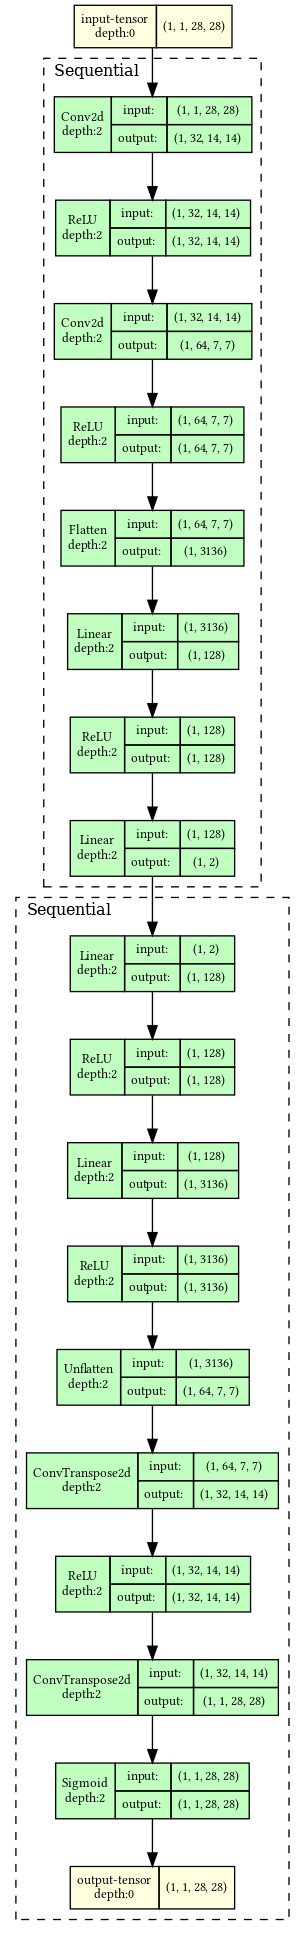

In [ ]:
# layer table and computational graph of the convolutional autoencoder (d = 2), without training;
# model creation and both dummy forward passes run inside fork_rng, so the global random generator is unchanged
from torchinfo import summary
from torchview import draw_graph
from IPython.display import Image, display
with torch.random.fork_rng(devices=[]):
    cae_view = ConvAE(2)
    info_conv = summary(cae_view, input_size=(1, 1, 28, 28), verbose=0)
    graph = draw_graph(cae_view, input_size=(1, 1, 28, 28), expand_nested=True, graph_name="ConvAE")
print(info_conv)
assert info_conv.total_params == sum(p.numel() for p in cae_view.parameters())
graph.visual_graph.attr(dpi="150")
png_path = graph.visual_graph.render(f"{RES}/arch_conv_ae_torchview", format="png", cleanup=True)
display(Image(filename=png_path))


### The latent space

The 16 latent numbers of each test image of the dense autoencoder with sixteen latent numbers are analysed with PCA and with t-SNE; the colours show the true digits and are used only for plotting. Do the digits form clusters in the latent space itself? To answer, we run k-means with ten clusters directly on the 16 latent numbers, on the t-SNE map of them and, for comparison, on the 50 PCA components of the pixels. The adjusted Rand indices are 0.284, 0.669 and 0.384: k-means on the raw latent vectors does worse than on the pixel components, and only on the t-SNE map do the clusters match the digits well.

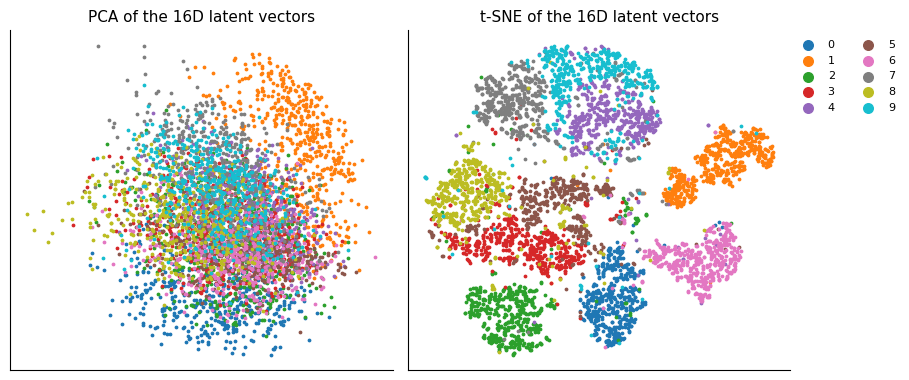

k-means (k=10), adjusted Rand index: directly on the 16 latent numbers 0.284 | on the t-SNE map of them 0.669 | on 50 PCA components of the pixels 0.384


In [15]:
with torch.no_grad():
    L16 = enc16(X5_t).numpy()                  # 16 latent numbers per test image
Lp = PCA(2).fit_transform(L16)
Lt = TSNE(2, perplexity=30, init="pca", random_state=0).fit_transform(L16)
nums["ae16_latent_kmeans_ari"] = float(adjusted_rand_score(y5, KMeans(10, n_init=10, random_state=0).fit(Lt).labels_))
ari_pixels = float(adjusted_rand_score(y5, KMeans(10, n_init=10, random_state=0).fit(Z).labels_))   # 50 PCA components of the pixels
nums["ae16_latent_kmeans_ari_direct"] = float(adjusted_rand_score(y5, KMeans(10, n_init=10, random_state=0).fit(L16).labels_))   # directly in the 16D latent space
fig, axs = plt.subplots(1, 2, figsize=(9, 3.9))
for a, P2, t in zip(axs, [Lp, Lt], ["PCA of the 16D latent vectors", "t-SNE of the 16D latent vectors"]):
    for dgt in range(10):
        m = y5 == dgt; a.scatter(P2[m, 0], P2[m, 1], s=3, color=cmap(dgt), label=str(dgt))
    a.set_title(t, fontsize=11); a.set_xticks([]); a.set_yticks([]); clean(a)
axs[1].legend(markerscale=4, fontsize=8, ncol=2, frameon=False, loc="upper right", bbox_to_anchor=(1.3, 1))
plt.tight_layout(); plt.savefig(f"{OUT}/gen_ae_latent16_maps.png", dpi=170, bbox_inches="tight"); plt.show()
print("k-means (k=10), adjusted Rand index: directly on the 16 latent numbers", round(nums["ae16_latent_kmeans_ari_direct"], 3), "| on the t-SNE map of them", round(nums["ae16_latent_kmeans_ari"], 3), "| on 50 PCA components of the pixels", round(ari_pixels, 3))

### A deeper convolutional autoencoder

A larger convolutional autoencoder with sixteen latent numbers has three convolutions (32, 64 and 128 channels, the last two with stride 2), batch normalisation, and a dense layer of 256 units to the 16 latent numbers; the decoder mirrors it. Does a better encoder give clearer clusters in the latent space? It is trained with its own random seed, and the generator is restored afterwards. Training takes about 45 minutes on a CPU (2724 s in the stored run), and the weights are saved for later runs.

The deeper network rebuilds the test digits with MSE 0.0068, about half the 0.0134 of the dense autoencoder with the same latent size. Its latent space is also much better organised: k-means matches the digits with ARI 0.566 directly on the 16 latent numbers and 0.912 on their t-SNE map, and the first two principal components of the latent vectors keep 31.3% of their variance.

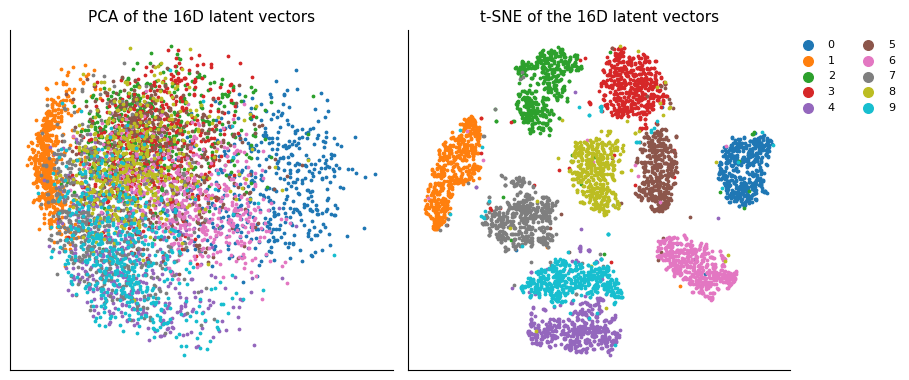

trained in 2724 s; {'dcae16_test_mse': 0.007, 'dcae16_pca2_var': 0.313, 'dcae16_kmeans_ari_direct': 0.566, 'dcae16_kmeans_ari_tsne': 0.912}


In [16]:
class DeepConvAE(nn.Module):
    def __init__(self, d=16):
        super().__init__()
        self.enc = nn.Sequential(nn.Conv2d(1, 32, 3, 1, 1), nn.BatchNorm2d(32), nn.ReLU(),
                                 nn.Conv2d(32, 64, 3, 2, 1), nn.BatchNorm2d(64), nn.ReLU(),
                                 nn.Conv2d(64, 128, 3, 2, 1), nn.BatchNorm2d(128), nn.ReLU(),
                                 nn.Flatten(), nn.Linear(128 * 7 * 7, 256), nn.ReLU(), nn.Linear(256, d))
        self.dec = nn.Sequential(nn.Linear(d, 256), nn.ReLU(), nn.Linear(256, 128 * 7 * 7), nn.ReLU(), nn.Unflatten(1, (128, 7, 7)),
                                 nn.ConvTranspose2d(128, 64, 3, 2, 1, output_padding=1), nn.BatchNorm2d(64), nn.ReLU(),
                                 nn.ConvTranspose2d(64, 32, 3, 2, 1, output_padding=1), nn.BatchNorm2d(32), nn.ReLU(),
                                 nn.Conv2d(32, 1, 3, 1, 1), nn.Sigmoid())
    def forward(self, x): return self.dec(self.enc(x))
state = torch.get_rng_state(); torch.manual_seed(3)
dcae = DeepConvAE(16); optd = torch.optim.Adam(dcae.parameters(), 1e-3); t0d = time.time()
for ep in range(15):
    dcae.train(); perm = torch.randperm(len(Xtr_img))
    for i in range(0, len(perm), 256):
        b = Xtr_img[perm[i:i + 256]]; loss = ((dcae(b) - b) ** 2).mean(); optd.zero_grad(); loss.backward(); optd.step()
torch.set_rng_state(state); dcae.eval()
torch.save(dcae.state_dict(), f"{RES}/deep_conv_ae16.pt")
with torch.no_grad():
    LD = dcae.enc(X5_t.reshape(-1, 1, 28, 28)).numpy()
    nums["dcae16_test_mse"] = float(((dcae(X5_t.reshape(-1, 1, 28, 28)) - X5_t.reshape(-1, 1, 28, 28)) ** 2).mean())
pD = PCA(2).fit(LD); LDp = pD.transform(LD); nums["dcae16_pca2_var"] = float(pD.explained_variance_ratio_.sum())
LDt = TSNE(2, perplexity=30, init="pca", random_state=0).fit_transform(LD)
nums["dcae16_kmeans_ari_direct"] = float(adjusted_rand_score(y5, KMeans(10, n_init=10, random_state=0).fit(LD).labels_))
nums["dcae16_kmeans_ari_tsne"] = float(adjusted_rand_score(y5, KMeans(10, n_init=10, random_state=0).fit(LDt).labels_))
fig, axs = plt.subplots(1, 2, figsize=(9, 3.9))
for a, P2, t in zip(axs, [LDp, LDt], ["PCA of the 16D latent vectors", "t-SNE of the 16D latent vectors"]):
    for dgt in range(10):
        m = y5 == dgt; a.scatter(P2[m, 0], P2[m, 1], s=3, color=cmap(dgt), label=str(dgt))
    a.set_title(t, fontsize=11); a.set_xticks([]); a.set_yticks([]); clean(a)
axs[1].legend(markerscale=4, fontsize=8, ncol=2, frameon=False, loc="upper right", bbox_to_anchor=(1.3, 1))
plt.tight_layout(); plt.savefig(f"{OUT}/gen_dcae_latent16_maps.png", dpi=170, bbox_inches="tight"); plt.show()
print(f"trained in {time.time() - t0d:.0f} s;", {k: round(nums[k], 3) for k in ["dcae16_test_mse", "dcae16_pca2_var", "dcae16_kmeans_ari_direct", "dcae16_kmeans_ari_tsne"]})


### Anomaly detection

An autoencoder trained only on *normal* data rebuilds similar samples well and unusual ones badly, so the reconstruction error
$$a(\mathbf x)=\big\lVert\mathbf x-G_{\boldsymbol\theta_D}\big(E_{\boldsymbol\theta_E}(\mathbf x)\big)\big\rVert^2 \tag{18}$$
is a score for how unusual a sample is. No example of an anomaly is needed for training.

To test the idea, we train the autoencoder (sixteen latent numbers) on all training digits except the 7s. For the network every 7 is then an unknown kind of image. We compute the reconstruction error of all 10 000 test digits and ask whether the 7s stand out. The random generator is saved and restored around this training, so the later results do not change.

The 7s do stand out, but only weakly. Their mean reconstruction error is 0.019, against 0.014 for the other digits, and the two histograms overlap strongly. A threshold that flags 5% of the normal digits catches only 12.9% of the 7s, and 24 of the 100 largest errors belong to 7s, which make up about 10% of the test set (1028 of 10 000). The 16 digits with the largest errors are shown below the histogram.

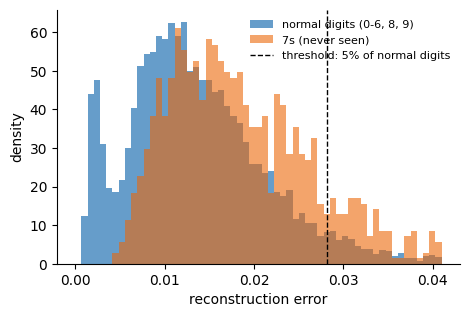

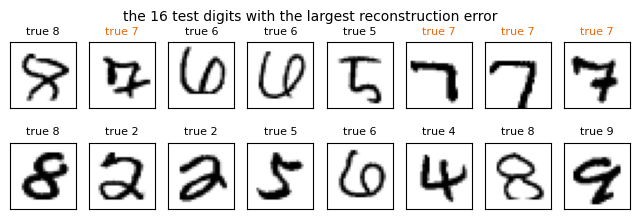

{'anom_err_normal': 0.014, 'anom_err_seven': 0.019, 'anom_frac7_flagged': 0.129, 'anom_auc': 0.678} | 7s among the 100 largest errors: 24


In [17]:
from sklearn.metrics import roc_auc_score
state = torch.get_rng_state(); torch.manual_seed(1)
encA, decA = train_ae(16, Xtr[ytr != 7], 15)               # "normal" data: every digit but 7
torch.set_rng_state(state)
Xte_t = torch.tensor(Xte, dtype=torch.float32)
with torch.no_grad():
    errA = ((decA(encA(Xte_t)) - Xte_t) ** 2).mean(1).numpy()
is7 = yte == 7
thr = np.percentile(errA[~is7], 95)                          # flags 5% of the normal digits
nums["anom_err_normal"] = float(errA[~is7].mean()); nums["anom_err_seven"] = float(errA[is7].mean())
nums["anom_frac7_flagged"] = float((errA[is7] > thr).mean())
nums["anom_auc"] = float(roc_auc_score(is7, errA))
top = np.argsort(errA)[::-1][:100]; nums["anom_top100_sevens"] = int(is7[top].sum())

fig, ax = plt.subplots(figsize=(5.2, 3.3))
bins = np.linspace(0, np.percentile(errA, 99.5), 60)
ax.hist(errA[~is7], bins=bins, density=True, alpha=0.6, color=blue, label="normal digits (0-6, 8, 9)")
ax.hist(errA[is7], bins=bins, density=True, alpha=0.6, color=orange, label="7s (never seen)")
ax.axvline(thr, color="k", ls="--", lw=1, label="threshold: 5% of normal digits")
ax.set_xlabel("reconstruction error"); ax.set_ylabel("density"); ax.legend(frameon=False, fontsize=8); clean(ax)
plt.savefig(f"{OUT}/gen_anomaly_hist.png", dpi=170, bbox_inches="tight"); plt.show()

fig, axs = plt.subplots(2, 8, figsize=(8, 2.4))
for j, a in enumerate(axs.ravel()):
    t = top[j]; a.imshow(Xte[t].reshape(28, 28), cmap="gray_r"); a.set_xticks([]); a.set_yticks([])
    a.set_title(f"true {yte[t]}", fontsize=8, color=orange if is7[t] else "k")
plt.suptitle("the 16 test digits with the largest reconstruction error", fontsize=10)
plt.savefig(f"{OUT}/gen_anomaly_top.png", dpi=170, bbox_inches="tight"); plt.show()
print({k: round(nums[k], 3) for k in ["anom_err_normal", "anom_err_seven", "anom_frac7_flagged", "anom_auc"]}, "| 7s among the 100 largest errors:", nums["anom_top100_sevens"])

### ROC curve and AUC

A single threshold on the anomaly score gives one decision rule; to judge the score itself we look at all thresholds at once. For each threshold we count the **true-positive rate** (TPR), the fraction of anomalies (here the 7s) above the threshold, i.e. found, and the **false-positive rate** (FPR), the fraction of normal digits above the threshold, i.e. false alarms.

Lowering the threshold from very high to very low traces the **ROC curve** (receiver operating characteristic) from $(0,0)$ to $(1,1)$. A useless score lies on the diagonal, with as many false alarms as hits; a perfect one goes straight up to a TPR of one at a vanishing FPR. The **AUC**, the area under this curve, is the probability that a randomly chosen anomaly has a larger score than a randomly chosen normal sample,
$$\mathrm{AUC}=P\big(a(\mathbf x_{\rm anomaly})>a(\mathbf x_{\rm normal})\big). \tag{19}$$
scikit-learn computes both: `roc_curve(y_true, score)` returns the FPR, the TPR and the thresholds, and `roc_auc_score(y_true, score)` the area.

For the unseen 7s the AUC is 0.68, well above chance (0.5) but far from perfect. The dot marks the threshold used above, at 5% false alarms and 12.9% of the 7s found.

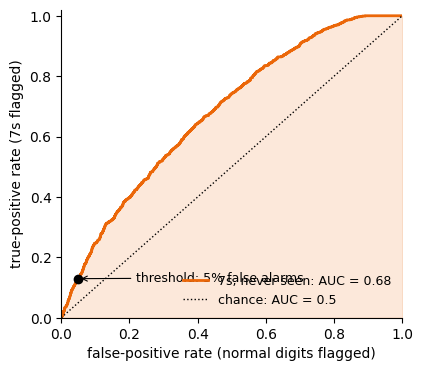

In [18]:
from sklearn.metrics import roc_curve
fpr, tpr, _ = roc_curve(is7, errA)
fig, ax = plt.subplots(figsize=(4.4, 4.0))
ax.fill_between(fpr, tpr, color=orange, alpha=0.15)
ax.plot(fpr, tpr, color=orange, lw=2, label=f"7s, never seen: AUC = {nums['anom_auc']:.2f}")
ax.plot([0, 1], [0, 1], "k:", lw=1, label="chance: AUC = 0.5")
ax.plot(0.05, nums["anom_frac7_flagged"], "o", color="k", ms=6)
ax.annotate("threshold: 5% false alarms", (0.05, nums["anom_frac7_flagged"]), xytext=(0.22, 0.12), fontsize=9, arrowprops=dict(arrowstyle="->", lw=0.8))
ax.set_xlabel("false-positive rate (normal digits flagged)"); ax.set_ylabel("true-positive rate (7s flagged)")
ax.set_xlim(0, 1); ax.set_ylim(0, 1.02); ax.legend(frameon=False, fontsize=9, loc="lower right"); clean(ax)
plt.savefig(f"{OUT}/gen_anomaly_roc.png", dpi=170, bbox_inches="tight"); plt.show()


## 5. k-means clustering

Dimensionality reduction shows groups to the eye; clustering assigns the samples to groups. k-means splits the samples into $k$ groups with centres $\boldsymbol\mu_c$ by minimising
$$\mathcal L=\sum_c\sum_{i\in S_c}\lVert\mathbf x_i-\boldsymbol\mu_c\rVert^2, \tag{20}$$
where $S_c$ is the set of samples in cluster $c$. It alternates two moves until nothing changes: assign every sample to its nearest centre, then move every centre to the mean of its samples. The number of groups $k$ is chosen by us.

We ask for ten groups, once on the 50 PCA components and once on the t-SNE map, and compare the groups with the true digits by the **adjusted Rand index** (ARI). It compares two partitions of the same $n$ samples, and the names of the groups do not matter. Look at all
$$\binom n2=\frac{n(n-1)}{2} \tag{21}$$
pairs of samples: a pair *agrees* if both partitions put it in the same group, or both put it in different groups. The Rand index $\mathrm{RI}$ is the fraction of agreeing pairs. Random groups already agree on many pairs, because most pairs are apart in both partitions, so the index is corrected for chance:
$$\mathrm{ARI}=\frac{\mathrm{RI}-\mathbb E[\mathrm{RI}]}{1-\mathbb E[\mathrm{RI}]}, \tag{22}$$
with $\mathbb E[\mathrm{RI}]$ the mean $\mathrm{RI}$ when the samples are reassigned at random, keeping the group sizes (Hubert & Arabie, 1985). The ARI is 1 for identical partitions, about 0 for random ones, and it can be negative.

On the 50 PCA components the ARI is 0.384, on the t-SNE map 0.762: clustering is much easier on the map, where the digits already form islands. The cluster centres found on the PCA components can be mapped back to pixel space with `pca.inverse_transform` and viewed as images; both figures are saved for the slides.

In [19]:
# k-means on MNIST: on 50 PCA components and on the t-SNE map
km = KMeans(10, n_init=10, random_state=0).fit(Z)
km_t = KMeans(10, n_init=10, random_state=0).fit(E)
nums["kmeans_ari_pca50"] = float(adjusted_rand_score(y5, km.labels_))
nums["kmeans_ari_tsne"] = float(adjusted_rand_score(y5, km_t.labels_))
cent = pca.inverse_transform(km.cluster_centers_)
fig, axs = plt.subplots(1, 10, figsize=(10, 1.3))
for k, a in enumerate(axs):
    a.imshow(cent[k].reshape(28, 28), cmap="gray_r"); a.set_xticks([]); a.set_yticks([])
    a.set_title(f"cluster {k+1}", fontsize=8)
plt.savefig(f"{OUT}/gen_kmeans_centroids.png", dpi=170, bbox_inches="tight"); plt.close()
fig, ax = plt.subplots(figsize=(4.6, 3.9))
for k in range(10):
    m = km_t.labels_ == k; ax.scatter(E[m, 0], E[m, 1], s=3, color=cmap(k))
ax.scatter(*km_t.cluster_centers_.T, marker="x", s=80, color="k")
ax.set_xticks([]); ax.set_yticks([]); ax.set_title("k-means, k = 10, on the t-SNE map", fontsize=11); clean(ax)
plt.savefig(f"{OUT}/gen_kmeans_tsne.png", dpi=170, bbox_inches="tight"); plt.close()
log("k-means done")
print({k: round(nums[k], 3) for k in ['kmeans_ari_pca50', 'kmeans_ari_tsne']})

[3136.4s] k-means done


{'kmeans_ari_pca50': 0.384, 'kmeans_ari_tsne': 0.762}


### k-means iterations

The two moves are best seen on five groups of points in 2D, shown first without colours: groups are visible, but where one ends and the next begins is not obvious. The loop implements k-means directly with NumPy. It starts from five centres placed badly on purpose, the five points nearest the lower-left corner, and alternates the two moves: every point joins its nearest centre (colours), then every centre moves to the mean of its points (crosses). We show snapshots until nothing changes, with the loss of equation (20) at each snapshot.

The loss falls from 28 559 at the start to 4429 after one iteration and to 1101 at convergence, reached after 11 iterations. The final groups match the true ones with ARI 0.93.

In [ ]:
from sklearn.datasets import make_blobs, make_moons
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score
# five groups in 2D; the five starting centres are the five points nearest the lower-left corner (a poor start)
Xb2, yb2 = make_blobs(500, centers=[[-4, -2], [-1, 3], [3, 4], [4, -2], [0, -4]], cluster_std=1.1, random_state=5)
fig, ax = plt.subplots(figsize=(4.6, 4.0))
ax.scatter(Xb2[:, 0], Xb2[:, 1], s=8, color="grey"); ax.set_xticks([]); ax.set_yticks([]); clean(ax)
plt.savefig(f"{OUT}/gen_kmeans_grey.png", dpi=170, bbox_inches="tight"); plt.show()
cen = Xb2[np.argsort(Xb2[:, 0] + Xb2[:, 1])[:5]].copy()
snaps = {}
for it in range(100):
    lab = np.argmin(((Xb2[:, None, :] - cen[None]) ** 2).sum(-1), 1)              # assign to the nearest centre
    snaps[it] = (lab.copy(), cen.copy(), float(((Xb2 - cen[lab]) ** 2).sum()))
    new = np.array([Xb2[lab == c].mean(0) for c in range(5)])                     # move the centres
    if np.allclose(new, cen): break
    cen = new
nums["kmeans_toy_iterations"] = it; nums["kmeans_toy_ari"] = float(adjusted_rand_score(yb2, lab))
show = [0, 1, 2, 3, 4, 6, 8, it]
fig, axs = plt.subplots(2, 4, figsize=(12, 6))
for a, k in zip(axs.ravel(), show):
    lab_k, cen_k, L_k = snaps[k]
    a.scatter(Xb2[:, 0], Xb2[:, 1], s=6, c=[cmap(l) for l in lab_k])
    a.scatter(cen_k[:, 0], cen_k[:, 1], marker="X", s=140, color="k", edgecolor="white", lw=1)
    a.set_title(("start" if k == 0 else f"iteration {k}") + (" (converged)" if k == it else "") + f"\nloss {L_k:.0f}", fontsize=14)
    a.set_xticks([]); a.set_yticks([]); clean(a)
plt.tight_layout(); plt.savefig(f"{OUT}/gen_kmeans_snapshots.png", dpi=170, bbox_inches="tight"); plt.show()
print(f"converged after {it} iterations; ARI with the true groups {nums['kmeans_toy_ari']:.2f}; loss:", [round(snaps[k][2]) for k in show])


/tmp/ipykernel_3955062/2037808786.py:8: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.savefig(f"{OUT}/gen_kmeans_grey.png", dpi=170, bbox_inches="tight"); plt.show()


converged after 11 iterations; ARI with the true groups 0.93; loss: [28559, 4429, 2663, 2043, 1869, 1767, 1326, 1101]


/tmp/ipykernel_3955062/2037808786.py:26: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.tight_layout(); plt.savefig(f"{OUT}/gen_kmeans_snapshots.png", dpi=170, bbox_inches="tight"); plt.show()


### k-means with scikit-learn

scikit-learn implements the same algorithm in `sklearn.cluster.KMeans`. The main parameters are `n_clusters` ($k$), `init` (the starting centres: `"k-means++"` by default, which spreads them out at random, `"random"`, or an explicit array), `n_init` (the number of starts, of which the one with the lowest loss is kept), `max_iter`, `tol` and `random_state`. After `fit(X)` the attributes `cluster_centers_`, `labels_`, `inertia_` (the loss $\mathcal L$) and `n_iter_` hold the result; `predict(X)` assigns new points to the nearest centre, and `fit_predict(X)` fits and returns the labels in one call. All later clusterings use `KMeans(k, n_init=10, random_state=0)`, ten starts from k-means++.

Started from the same five poor centres, with a single start and `tol=0` so that it stops only when the assignment no longer changes, scikit-learn's Lloyd algorithm performs the same alternating moves as our loop. Labels, centres and loss must therefore agree exactly, which an assertion checks. All 500 labels agree, the centres differ by at most $8.9\times10^{-16}$, and both losses are 1101.295065. scikit-learn reports 12 iterations against our 11 because it also counts the final pass in which no label changes.

In [ ]:
# k-means with scikit-learn, started from the same five centres as the loop above
start5 = Xb2[np.argsort(Xb2[:, 0] + Xb2[:, 1])[:5]]                            # the same poor start
km_skl = KMeans(n_clusters=5, init=start5, n_init=1, algorithm="lloyd", tol=0).fit(Xb2)
print("iterations: loop above", it, "| scikit-learn", km_skl.n_iter_)
print("points with a different label:", int((km_skl.labels_ != lab).sum()))
print(f"max |difference| of the centres: {np.abs(km_skl.cluster_centers_ - cen).max():.1e}")
print(f"loss: loop above {snaps[it][2]:.6f} | scikit-learn inertia_ {km_skl.inertia_:.6f}")
assert (km_skl.labels_ == lab).all()
assert np.allclose(km_skl.cluster_centers_, cen, rtol=0, atol=1e-10)
assert abs(km_skl.inertia_ - snaps[it][2]) < 1e-8 * snaps[it][2]

iterations: loop above 11 | scikit-learn 12
points with a different label: 0
max |difference| of the centres: 8.9e-16
loss: loop above 1101.295065 | scikit-learn inertia_ 1101.295065


### Choosing $k$

k-means needs $k$ from us, and two common guides help to choose it. The first is the **elbow**: the loss of equation (20), as a function $\mathcal L(k)$ of the number of clusters, always decreases when $k$ grows, since more centres mean shorter distances, and we look for the $k$ after which it decreases only slowly. The second is the **silhouette score**. For each point, $a$ is its mean distance to the other points of its own cluster and $b$ the mean distance to the points of the nearest other cluster; the silhouette
$$s=\frac{b-a}{\max(a,b)} \tag{23}$$
lies between $-1$ and $1$, and is close to 1 when the point sits well inside its cluster and far from the others. We average $s$ over the points and pick the $k$ with the highest average.

The procedure is then: for every $k$ from 2 upwards run k-means (several random starts, keeping the lowest loss), record the loss $\mathcal L(k)$ and the mean silhouette $\bar s(k)$, and plot both against $k$. The sketch shows the two distances of the silhouette for one point $\mathbf x_i$: its own cluster of 12 points (11 besides $\mathbf x_i$), the nearest other cluster and a third cluster farther away. With $a_i$ of 0.84 and $b_i$ of 2.15 the point has
$$s_i=\frac{2.15-0.84}{2.15}=0.61 . \tag{24}$$

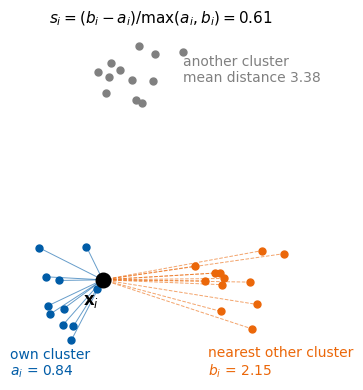

a_i = 0.84, b_i = 2.15, s_i = 0.61


In [21]:
rs = np.random.default_rng(5)
own   = rs.normal([0.0, 0.0], 0.45, (12, 2))     # the cluster of point i
near  = rs.normal([3.0, 0.3], 0.45, (12, 2))     # the nearest other cluster
far   = rs.normal([0.8, 3.6], 0.45, (12, 2))     # another cluster
xi = np.array([0.6, 0.2]); others = own[1:]
a_i = np.linalg.norm(others - xi, axis=1).mean()                 # mean distance inside its own cluster
b_near = np.linalg.norm(near - xi, axis=1).mean(); b_far = np.linalg.norm(far - xi, axis=1).mean()
b_i = min(b_near, b_far)                                         # the nearest other cluster
s_i = (b_i - a_i) / max(a_i, b_i)
fig, ax = plt.subplots(figsize=(5.2, 4.2))
for q in others: ax.plot([xi[0], q[0]], [xi[1], q[1]], color=blue, lw=0.7, alpha=0.6)
for q in near:   ax.plot([xi[0], q[0]], [xi[1], q[1]], color=orange, lw=0.7, alpha=0.6, ls="--")
ax.scatter(*others.T, s=25, color=blue); ax.scatter(*near.T, s=25, color=orange); ax.scatter(*far.T, s=25, color="grey")
ax.scatter(*xi, s=110, color="k", zorder=5); ax.annotate(r"$\mathbf{x}_i$", xi, xytext=(-14, -18), textcoords="offset points", fontsize=12)
ax.text(-0.9, -1.35, f"own cluster\n$a_i$ = {a_i:.2f}", color=blue, fontsize=10)
ax.text(2.3, -1.35, f"nearest other cluster\n$b_i$ = {b_i:.2f}", color=orange, fontsize=10)
ax.text(1.9, 3.4, f"another cluster\nmean distance {b_far:.2f}", color="grey", fontsize=10)
ax.set_title(rf"$s_i = (b_i - a_i)/\max(a_i, b_i) = {s_i:.2f}$", fontsize=11)
ax.set_aspect("equal"); ax.axis("off")
plt.savefig(f"{OUT}/gen_silhouette_sketch.png", dpi=170, bbox_inches="tight"); plt.show()
print(f"a_i = {a_i:.2f}, b_i = {b_i:.2f}, s_i = {s_i:.2f}")


### Silhouette with scikit-learn

In scikit-learn, `sklearn.metrics.silhouette_samples(X, labels)` returns $s_i$ for every point and `silhouette_score(X, labels)` their mean; with `sample_size` the mean is taken over a random subset, which saves time on large data, and `metric` sets the distance (Euclidean by default). We give `silhouette_samples` the 36 points of the sketch with their three cluster labels and compare its value for $\mathbf x_i$ with the one computed above; the formula is the same, so they must agree to rounding. Both give the value 0.607307405991 for $s_i$; the difference is 0 to twelve decimals.

In [ ]:
# silhouette with scikit-learn: the black point together with the three clusters of the sketch
from sklearn.metrics import silhouette_samples
pts_sil = np.vstack([xi, others, near, far])                                  # x_i first, then its own cluster
lab_sil = np.r_[np.zeros(1 + len(others)), np.ones(len(near)), 2 * np.ones(len(far))]
s_skl = silhouette_samples(pts_sil, lab_sil)
print(f"s_i: computed above {s_i:.12f} | scikit-learn {s_skl[0]:.12f} | difference {abs(s_skl[0] - s_i):.1e}")
assert abs(s_skl[0] - s_i) < 1e-10

s_i: computed above 0.607307405991 | scikit-learn 0.607307405991 | difference 0.0e+00


Both guides are tried on 600 points drawn around four centres. For every $k$ from 2 to 8, k-means is run with ten starts; the figure shows the clusterings into 2, 4 and 6 clusters and the two curves. The loss bends at four clusters (the elbow), and the silhouette is highest at four, the true number of groups.

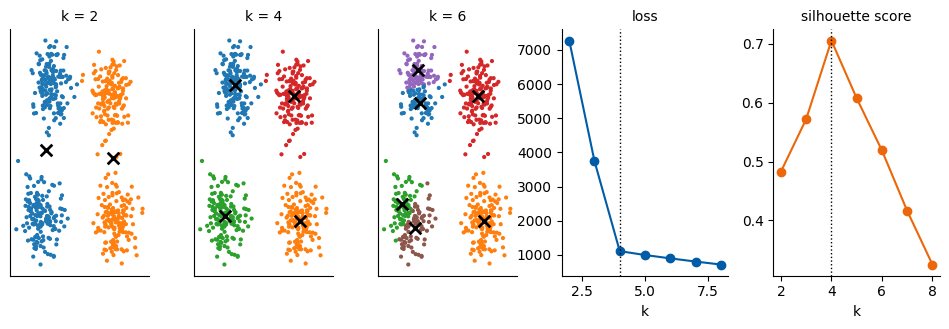

best k by silhouette: 4


In [22]:
Xk, _ = make_blobs(600, centers=[[-4, -3], [-3, 3.5], [3, 3], [3.5, -3]], cluster_std=1.0, random_state=4)
ks4 = list(range(2, 9)); in4, si4, labs4 = [], [], {}
for kk in ks4:
    km4 = KMeans(kk, n_init=10, random_state=0).fit(Xk)
    in4.append(km4.inertia_); si4.append(silhouette_score(Xk, km4.labels_)); labs4[kk] = (km4.labels_, km4.cluster_centers_)
nums["toy4_best_k_silhouette"] = int(ks4[int(np.argmax(si4))])
fig = plt.figure(figsize=(12, 3.2)); gsk = fig.add_gridspec(1, 5, width_ratios=[1, 1, 1, 1.2, 1.2], wspace=0.3)
for j, kk in enumerate([2, 4, 6]):
    a = fig.add_subplot(gsk[0, j]); lab, cen = labs4[kk]
    a.scatter(Xk[:, 0], Xk[:, 1], s=4, c=[cmap(l) for l in lab]); a.scatter(cen[:, 0], cen[:, 1], marker="x", s=70, color="k", lw=2)
    a.set_title(f"k = {kk}", fontsize=10); a.set_xticks([]); a.set_yticks([]); clean(a)
a = fig.add_subplot(gsk[0, 3]); a.plot(ks4, in4, "o-", color=blue); a.axvline(4, color="k", ls=":", lw=1); a.set_title("loss", fontsize=10); a.set_xlabel("k"); clean(a)
a = fig.add_subplot(gsk[0, 4]); a.plot(ks4, si4, "o-", color=orange); a.axvline(4, color="k", ls=":", lw=1); a.set_title("silhouette score", fontsize=10); a.set_xlabel("k"); clean(a)
plt.savefig(f"{OUT}/gen_kmeans_choose_k_toy.png", dpi=170, bbox_inches="tight"); plt.show()
print("best k by silhouette:", nums["toy4_best_k_silhouette"])

### Rand index

The same 600 points show how the Rand index and its adjusted form judge different partitions. We compare the true groups with three clusterings: k-means with four clusters, a too coarse k-means with two, and random group labels. The scores come from `sklearn.metrics.rand_score` and `adjusted_rand_score`, which take the two label vectors in any order and ignore the names of the groups. The clustering into four gives RI 0.997 and ARI 0.991, and the one into two gives RI 0.750 and ARI 0.499. The random labels still reach RI 0.626, because most pairs are apart in both partitions; the adjustment for chance brings them to ARI 0.000.

In [23]:
# the adjusted Rand index on the four groups: true groups and three clusterings
from sklearn.datasets import make_blobs
from sklearn.metrics import rand_score
Xa, ya = make_blobs(600, centers=[[-4, -3], [-3, 3.5], [3, 3], [3.5, -3]], cluster_std=1.0, random_state=4)   # the same points as above
ra = np.random.default_rng(7)
parts = [("true groups", ya),
         ("k-means, k = 4", KMeans(4, n_init=10, random_state=0).fit(Xa).labels_),
         ("k-means, k = 2", KMeans(2, n_init=10, random_state=0).fit(Xa).labels_),
         ("random groups", ra.integers(0, 4, len(Xa)))]
fig, axs = plt.subplots(1, 4, figsize=(11, 2.9))
for a, (t, lab) in zip(axs, parts):
    a.scatter(Xa[:, 0], Xa[:, 1], s=4, c=[cmap(l) for l in lab]); a.set_xticks([]); a.set_yticks([]); clean(a)
    a.set_title(t if t == "true groups" else f"{t}\nRI = {rand_score(ya, lab):.2f}, ARI = {adjusted_rand_score(ya, lab):.2f}", fontsize=14)
plt.tight_layout(); plt.savefig(f"{OUT}/gen_ari_toy.png", dpi=170, bbox_inches="tight"); plt.show()
for t, lab in parts[1:]: print(f"{t}: RI {rand_score(ya, lab):.3f}, ARI {adjusted_rand_score(ya, lab):.3f}")


k-means, k = 4: RI 0.997, ARI 0.991
k-means, k = 2: RI 0.750, ARI 0.499
random groups: RI 0.626, ARI -0.000


/tmp/ipykernel_3955062/2671005340.py:14: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.tight_layout(); plt.savefig(f"{OUT}/gen_ari_toy.png", dpi=170, bbox_inches="tight"); plt.show()


The Rand index can be checked by counting pairs. On the slides it is illustrated with six points with true labels $\{1,2,3\},\{4,5,6\}$ and clusters $\{1,2\},\{3,4,5\},\{6\}$. Of the 15 pairs, $a$, here 2, are together in both partitions and $b$, here 7, apart in both, so
$$\mathrm{RI}=\frac{a+b}{15}=\frac{9}{15}=0.60 ; \tag{25}$$
the adjusted index is only 0.12.

In [ ]:
# the six points of the Rand-index sketch: labels {1,2,3},{4,5,6}; clusters {1,2},{3,4,5},{6}
from itertools import combinations
from sklearn.metrics import rand_score
lab6, clu6 = [0, 0, 0, 1, 1, 1], [0, 0, 1, 1, 1, 2]
pairs = {"together in both": [], "apart in both": [], "disagree": []}
for i, j in combinations(range(6), 2):
    same_l, same_c = lab6[i] == lab6[j], clu6[i] == clu6[j]
    pairs["together in both" if same_l and same_c else "apart in both" if not (same_l or same_c) else "disagree"].append(f"{i + 1}-{j + 1}")
for k, v in pairs.items(): print(f"{k}: {len(v)}  {v}")
nums["ri_sketch"], nums["ari_sketch"] = float(rand_score(lab6, clu6)), float(adjusted_rand_score(lab6, clu6))
print(f"RI = {nums['ri_sketch']:.2f}, ARI = {nums['ari_sketch']:.2f}")


together in both: 2  ['1-2', '4-5']
apart in both: 7  ['1-4', '1-5', '1-6', '2-4', '2-5', '2-6', '3-6']
disagree: 6  ['1-3', '2-3', '3-4', '3-5', '4-6', '5-6']
RI = 0.60, ARI = 0.12


### Rand index with scikit-learn

Besides `rand_score` and `adjusted_rand_score`, scikit-learn exposes the pair counts themselves through `sklearn.metrics.cluster.pair_confusion_matrix(labels_true, labels_pred)`. It returns a $2\times2$ matrix whose entry $[0,0]$ counts pairs apart in both partitions, $[1,1]$ pairs together in both, and the off-diagonal entries the disagreements; it counts ordered pairs, so every pair appears twice. We check that it reproduces the counts listed above and that the fraction of agreeing pairs equals `rand_score`. scikit-learn finds the same 7 pairs apart in both, 2 together in both and 6 disagreeing, and both routes give an RI of exactly 0.6.

In [ ]:
# Rand index with scikit-learn: the pair counts and the index from them
from sklearn.metrics.cluster import pair_confusion_matrix
pcm = pair_confusion_matrix(lab6, clu6) // 2                                   # scikit-learn counts ordered pairs, i.e. each pair twice
print("apart in both", pcm[0, 0], "| together in both", pcm[1, 1], "| disagree", pcm[0, 1] + pcm[1, 0])
ri_pairs = (pcm[0, 0] + pcm[1, 1]) / pcm.sum()
print(f"RI from the pair counts {ri_pairs:.12f} | rand_score {rand_score(lab6, clu6):.12f}")
assert pcm[1, 1] == len(pairs["together in both"]) and pcm[0, 0] == len(pairs["apart in both"])
assert pcm[0, 1] + pcm[1, 0] == len(pairs["disagree"])
assert abs(ri_pairs - rand_score(lab6, clu6)) < 1e-10 and abs(ri_pairs - 9 / 15) < 1e-12

apart in both 7 | together in both 2 | disagree 6
RI from the pair counts 0.600000000000 | rand_score 0.600000000000


### Choosing $k$ on MNIST

On the t-SNE map of the 5000 MNIST digits the answer is less clear-cut. We repeat the procedure for 2 to 15 clusters, with the silhouette averaged over a random subset of 3000 points to save time. The dotted line marks ten clusters, the number of digits; it is drawn only for comparison, since k-means and the two guides do not know the labels. The loss decreases smoothly without a clear elbow. The silhouette rises to a plateau between 8 and 11 clusters and is highest at 11, close to, but not equal to, the number of digits.

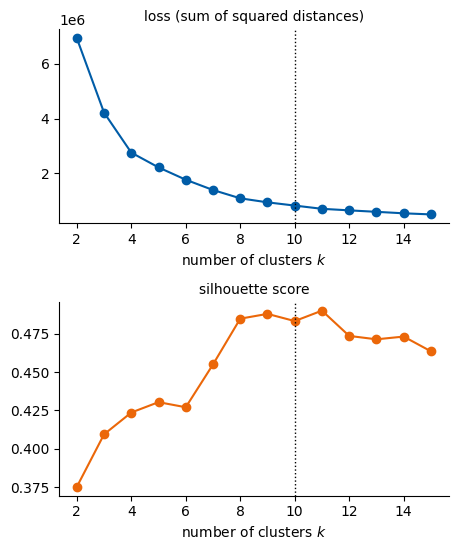

k with the highest silhouette: 11


In [24]:
ks = list(range(2, 16)); inert, sil = [], []
for kk in ks:
    kmk = KMeans(kk, n_init=10, random_state=0).fit(E)
    inert.append(kmk.inertia_); sil.append(silhouette_score(E, kmk.labels_, sample_size=3000, random_state=0))
nums["kmeans_best_k_silhouette"] = int(ks[int(np.argmax(sil))])
fig, axs = plt.subplots(2, 1, figsize=(4.6, 5.6))
axs[0].plot(ks, inert, "o-", color=blue); axs[0].set_title("loss (sum of squared distances)", fontsize=10)
axs[1].plot(ks, sil, "o-", color=orange); axs[1].set_title("silhouette score", fontsize=10)
for a in axs: a.set_xlabel("number of clusters $k$"); a.axvline(10, color="k", ls=":", lw=1); clean(a)
plt.tight_layout(); plt.savefig(f"{OUT}/gen_kmeans_choose_k.png", dpi=170, bbox_inches="tight"); plt.show()
print("k with the highest silhouette:", nums["kmeans_best_k_silhouette"])

### DBSCAN

k-means cuts space into convex cells around the centres, so it finds round clusters. **DBSCAN** (density-based spatial clustering of applications with noise; Ester et al., 1996) instead grows clusters from dense regions. It has two parameters, a radius $\varepsilon$ and a minimum number of points $m$. A **core point** has at least $m$ points, itself included, within distance $\varepsilon$. A **border point** is not a core point but lies within $\varepsilon$ of one. Every other point is **noise**. A cluster is a set of core points that can be reached from each other in steps shorter than $\varepsilon$, together with their border points. DBSCAN therefore needs no number of clusters, follows clusters of any shape and leaves isolated points unassigned.

We use `sklearn.cluster.DBSCAN(eps, min_samples)`, where `min_samples` is our $m$ and counts the point itself. After `fit(X)`, `labels_` holds the cluster of every point, with $-1$ for noise, and `core_sample_indices_` the indices of the core points; `fit_predict(X)` returns the labels directly.

A small example comes first: 70 points on two half-moons and 8 scattered points, with the radius 0.25 and at least four points. DBSCAN finds 3 clusters, with 65 core points, 4 border points and 9 noise points. Then 500 points on two interlocking half-moons, where k-means with two clusters cuts straight across the moons (ARI 0.25), while DBSCAN with the radius 0.2 and at least five points recovers them exactly (ARI 1.00).

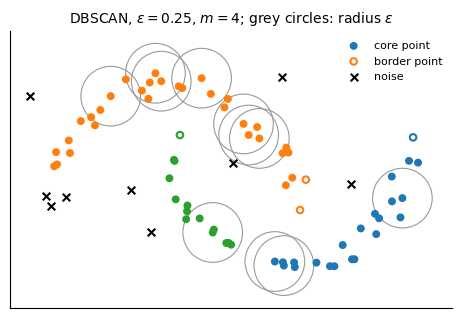

clusters: 3 | core 65 | border 4 | noise 9


In [25]:
rd = np.random.default_rng(7)
Xd = np.r_[make_moons(70, noise=0.07, random_state=1)[0], rd.uniform([-1.2, -0.8], [2.2, 1.3], (8, 2))]
eps_d, m_d = 0.25, 4
db = DBSCAN(eps=eps_d, min_samples=m_d).fit(Xd)
core = np.zeros(len(Xd), bool); core[db.core_sample_indices_] = True
noise = db.labels_ == -1; border = ~core & ~noise
fig, ax = plt.subplots(figsize=(6.2, 3.6))
for i in np.flatnonzero(core)[::6]:
    ax.add_patch(plt.Circle(Xd[i], eps_d, fill=False, color="#999999", lw=0.8))
ax.scatter(*Xd[core].T, s=22, c=[cmap(l) for l in db.labels_[core]], label="core point")
ax.scatter(*Xd[border].T, s=22, facecolors="white", edgecolors=[cmap(l) for l in db.labels_[border]], lw=1.5, label="border point")
ax.scatter(*Xd[noise].T, s=30, marker="x", color="k", label="noise")
ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([]); ax.legend(frameon=False, fontsize=8, loc="upper right"); clean(ax)
ax.set_title(rf"DBSCAN, $\varepsilon = {eps_d}$, $m = {m_d}$; grey circles: radius $\varepsilon$", fontsize=10)
plt.savefig(f"{OUT}/gen_dbscan_sketch.png", dpi=170, bbox_inches="tight"); plt.show()
print("clusters:", len(set(db.labels_)) - (1 if -1 in db.labels_ else 0), "| core", core.sum(), "| border", border.sum(), "| noise", noise.sum())

In [26]:
Xm, ym = make_moons(500, noise=0.06, random_state=0)
lab_km = KMeans(2, n_init=10, random_state=0).fit_predict(Xm)
lab_db = DBSCAN(eps=0.2, min_samples=5).fit_predict(Xm)
nums["moons_ari_kmeans"] = float(adjusted_rand_score(ym, lab_km)); nums["moons_ari_dbscan"] = float(adjusted_rand_score(ym, lab_db))
fig, axs = plt.subplots(1, 2, figsize=(8.5, 3.0))
for a, lab, t in zip(axs, [lab_km, lab_db], [f"k-means, k = 2 (ARI {nums['moons_ari_kmeans']:.2f})", f"DBSCAN (ARI {nums['moons_ari_dbscan']:.2f})"]):
    a.scatter(Xm[:, 0], Xm[:, 1], s=6, c=[cmap(l % 10) if l >= 0 else "grey" for l in lab]); a.set_title(t, fontsize=14)
    a.set_xticks([]); a.set_yticks([]); clean(a)
plt.tight_layout(); plt.savefig(f"{OUT}/gen_kmeans_moons.png", dpi=170, bbox_inches="tight"); plt.show()

/tmp/ipykernel_3955062/535183089.py:9: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.tight_layout(); plt.savefig(f"{OUT}/gen_kmeans_moons.png", dpi=170, bbox_inches="tight"); plt.show()


### Exercise

Run k-means with 5 and with 15 clusters on the t-SNE map. Which digits are merged, which are split?

## 6. CIFAR-10

CIFAR-10 (Canadian Institute for Advanced Research, 10 classes; [Krizhevsky, *Learning multiple layers of features from tiny images*, technical report, University of Toronto (2009)](https://www.cs.toronto.edu/~kriz/cifar.html); Lecture 4) consists of 60 000 colour photographs, 50 000 for training and 10 000 for testing, 6000 per class. One sample is a $32\times32$ image with three colour channels (red, green, blue), each pixel value an integer from 0 to 255, so that the dimension of the data is
$$D = 32\cdot32\cdot3 = 3072 ; \tag{26}$$
the label is one of airplane, automobile, bird, cat, deer, dog, frog, horse, ship and truck. We apply PCA, t-SNE and an autoencoder exactly as for MNIST. The data (170 MB) are downloaded once and reused on later runs. Separate random generators are used, so the later results do not change.

PCA is fitted on 20 000 training images and applied to 5000 test images; the first two components keep 40.3% of the variance, more than for MNIST, because neighbouring pixels of a photograph and its three colour channels are strongly correlated. Yet the classes do not separate: k-means with ten clusters on the t-SNE map matches them with ARI 0.051, hardly above chance.

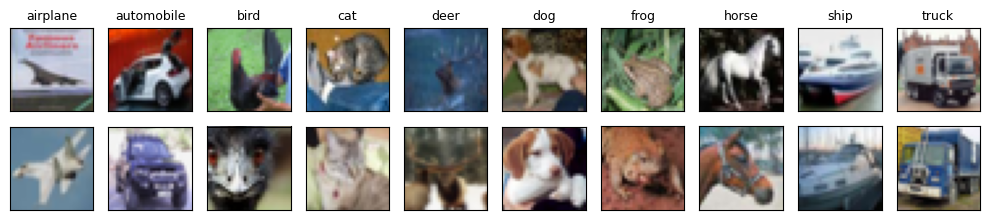

test photographs: (10000, 32, 32, 3) | per class: [1000 1000 1000 1000 1000 1000 1000 1000 1000 1000]


In [ ]:
# two CIFAR-10 test photographs of every class (the data are downloaded here the first time)
import pickle, tarfile, urllib.request
cdir_ = "data/cifar-10-batches-py"
if not os.path.isdir(cdir_):
    os.makedirs("data", exist_ok=True)
    urllib.request.urlretrieve("https://www.cs.toronto.edu/~kriz/cifar-10-python.tar.gz", "data/cifar-10-python.tar.gz")
    tarfile.open("data/cifar-10-python.tar.gz").extractall("data")
tb_ = pickle.load(open(os.path.join(cdir_, "test_batch"), "rb"), encoding="bytes")
cimg_ = tb_[b"data"].reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1); clab_ = np.array(tb_[b"labels"])
cnames_ = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]
fig, axs = plt.subplots(2, 10, figsize=(10, 2.4))
for c in range(10):
    for r, k in enumerate(np.flatnonzero(clab_ == c)[:2]):
        axs[r, c].imshow(cimg_[k]); axs[r, c].set_xticks([]); axs[r, c].set_yticks([])
    axs[0, c].set_title(cnames_[c], fontsize=9)
plt.tight_layout(); plt.show()
print("test photographs:", cimg_.shape, "| per class:", np.bincount(clab_))


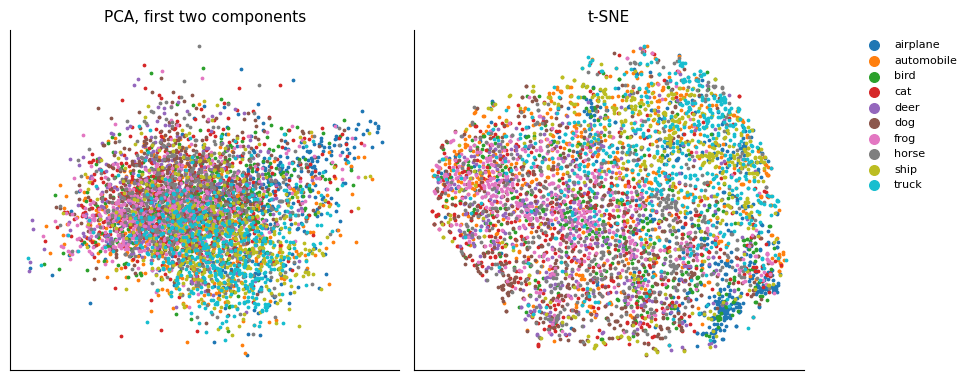

{'cifar_pca_var2': 0.403, 'cifar_kmeans_ari_tsne': 0.051}


In [27]:
import pickle, tarfile, urllib.request
cdir = "data/cifar-10-batches-py"
if not os.path.isdir(cdir):
    os.makedirs("data", exist_ok=True)
    urllib.request.urlretrieve("https://www.cs.toronto.edu/~kriz/cifar-10-python.tar.gz", "data/cifar-10-python.tar.gz")
    tarfile.open("data/cifar-10-python.tar.gz").extractall("data")
def cbatch(name):
    d = pickle.load(open(os.path.join(cdir, name), "rb"), encoding="bytes")
    return d[b"data"].astype(np.float32) / 255.0, np.array(d[b"labels"])
parts = [cbatch(f"data_batch_{i}") for i in range(1, 6)]
Ctr = np.concatenate([p_[0] for p_ in parts]); cytr = np.concatenate([p_[1] for p_ in parts])
Cte, cyte = cbatch("test_batch")
cnames = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]
rc = np.random.default_rng(5); csel = rc.choice(len(Cte), 5000, replace=False)
C5, cy5 = Cte[csel], cyte[csel]
cpca = PCA(50, random_state=0).fit(Ctr[rc.choice(len(Ctr), 20000, replace=False)])
CZ = cpca.transform(C5); nums["cifar_pca_var2"] = float(cpca.explained_variance_ratio_[:2].sum())
CE = TSNE(2, perplexity=30, init="pca", random_state=0).fit_transform(CZ)
nums["cifar_kmeans_ari_tsne"] = float(adjusted_rand_score(cy5, KMeans(10, n_init=10, random_state=0).fit(CE).labels_))
fig, axs = plt.subplots(1, 2, figsize=(9.6, 3.9))
for a, P2, t in zip(axs, [CZ[:, :2], CE], ["PCA, first two components", "t-SNE"]):
    for c in range(10):
        m = cy5 == c; a.scatter(P2[m, 0], P2[m, 1], s=3, color=cmap(c), label=cnames[c])
    a.set_title(t, fontsize=11); a.set_xticks([]); a.set_yticks([]); clean(a)
axs[1].legend(markerscale=4, fontsize=8, frameon=False, loc="upper right", bbox_to_anchor=(1.42, 1))
plt.tight_layout(); plt.savefig(f"{OUT}/gen_cifar_pca_tsne.png", dpi=170, bbox_inches="tight"); plt.show()
print({k: round(nums[k], 3) for k in ["cifar_pca_var2", "cifar_kmeans_ari_tsne"]})

An autoencoder for CIFAR-10 has dense layers $3072\to512\to128\to32$ and back and is trained for 10 epochs. The figure shows eight test photographs with their reconstructions from 32 latent numbers, and a t-SNE map of the latent vectors. The reconstructions keep the colours and the rough layout but lose the details (test MSE 0.0163), and the latent space does not separate the classes either (k-means ARI 0.044).

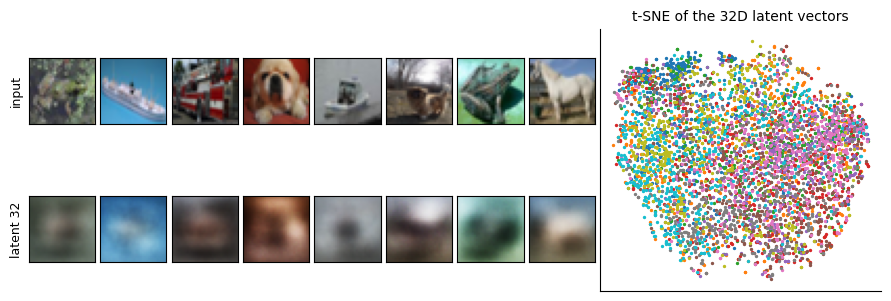

{'cifar_ae_test_mse': 0.0163, 'cifar_ae_latent_ari': 0.0439}


In [28]:
def train_ae_c(latent, X, epochs, lr=1e-3):
    enc = nn.Sequential(nn.Linear(3072, 512), nn.ReLU(), nn.Linear(512, 128), nn.ReLU(), nn.Linear(128, latent))
    dec = nn.Sequential(nn.Linear(latent, 128), nn.ReLU(), nn.Linear(128, 512), nn.ReLU(), nn.Linear(512, 3072), nn.Sigmoid())
    opt = torch.optim.Adam(list(enc.parameters()) + list(dec.parameters()), lr=lr)
    Xt = torch.tensor(X)
    for ep in range(epochs):
        perm = torch.randperm(len(Xt))
        for i in range(0, len(Xt), 256):
            b = Xt[perm[i:i + 256]]; loss = ((dec(enc(b)) - b) ** 2).mean(); opt.zero_grad(); loss.backward(); opt.step()
    return enc, dec
state = torch.get_rng_state(); torch.manual_seed(2)
encC, decC = train_ae_c(32, Ctr, 10)
torch.set_rng_state(state)
C5_t = torch.tensor(C5)
with torch.no_grad():
    LC = encC(C5_t).numpy(); RC = decC(encC(C5_t[:8])).numpy(); nums["cifar_ae_test_mse"] = float(((decC(encC(C5_t)) - C5_t) ** 2).mean())
LCt = TSNE(2, perplexity=30, init="pca", random_state=0).fit_transform(LC)
nums["cifar_ae_latent_ari"] = float(adjusted_rand_score(cy5, KMeans(10, n_init=10, random_state=0).fit(LCt).labels_))
img = lambda v: v.reshape(3, 32, 32).transpose(1, 2, 0)
fig = plt.figure(figsize=(11, 3.4)); gs = fig.add_gridspec(2, 12, wspace=0.08, hspace=0.12)
for j in range(8):
    for r, src in enumerate([C5[j], RC[j]]):
        a = fig.add_subplot(gs[r, j]); a.imshow(img(src)); a.set_xticks([]); a.set_yticks([])
        if j == 0: a.set_ylabel(["input", "latent 32"][r], fontsize=9)
a = fig.add_subplot(gs[:, 8:])
for c in range(10):
    m = cy5 == c; a.scatter(LCt[m, 0], LCt[m, 1], s=2, color=cmap(c))
a.set_title("t-SNE of the 32D latent vectors", fontsize=10); a.set_xticks([]); a.set_yticks([]); clean(a)
plt.savefig(f"{OUT}/gen_cifar_ae.png", dpi=170, bbox_inches="tight"); plt.show()
print({k: round(nums[k], 4) for k in ["cifar_ae_test_mse", "cifar_ae_latent_ari"]})

### Exercise

Compare with MNIST: why are the CIFAR-10 classes so much harder to separate from the pixels? Train the CNN of Lecture 4 and run t-SNE on its last hidden layer instead.

### Photographs among digits

The 7s were a subtle anomaly: they share strokes with 1s and 9s, so the autoencoder rebuilds many of them well. A very different kind of input is the CIFAR-10 photographs, converted to $28\times28$ grayscale and given to the autoencoder trained on **all** MNIST digits (sixteen latent numbers). We set the threshold so that 5% of the MNIST test digits are flagged and ask how many photographs exceed it. Practically all do: 99.8% of the photographs are flagged, and the AUC is 0.999.

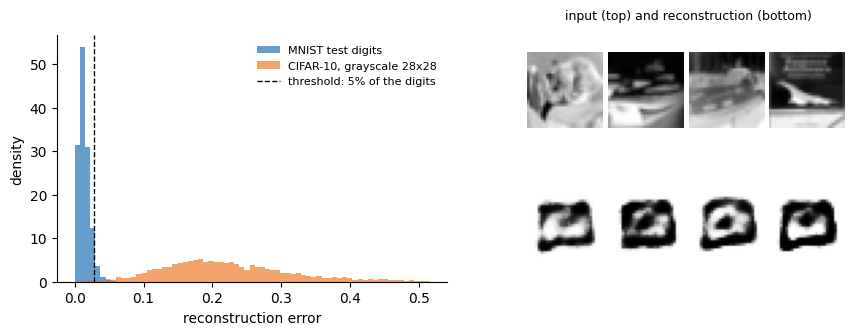

{'ood_frac_flagged': 0.998, 'ood_auc': 0.999}


In [29]:
import torch.nn.functional as Fnn
gray = (0.299 * Cte[:, :1024] + 0.587 * Cte[:, 1024:2048] + 0.114 * Cte[:, 2048:]).reshape(-1, 1, 32, 32)
ood = Fnn.interpolate(torch.tensor(gray[:5000]), size=(28, 28), mode="bilinear", align_corners=False).reshape(-1, 784)
with torch.no_grad():
    err_in = ((dec16(enc16(Xte_t)) - Xte_t) ** 2).mean(1).numpy()
    err_ood = ((dec16(enc16(ood)) - ood) ** 2).mean(1).numpy()
thr_in = np.percentile(err_in, 95)
nums["ood_frac_flagged"] = float((err_ood > thr_in).mean())
nums["ood_auc"] = float(roc_auc_score(np.r_[np.zeros(len(err_in)), np.ones(len(err_ood))], np.r_[err_in, err_ood]))
fig, axs = plt.subplots(1, 2, figsize=(9.5, 3.2), gridspec_kw=dict(width_ratios=[1.4, 1]))
bins = np.linspace(0, np.percentile(np.r_[err_in, err_ood], 99.5), 70)
axs[0].hist(err_in, bins=bins, density=True, alpha=0.6, color=blue, label="MNIST test digits")
axs[0].hist(err_ood, bins=bins, density=True, alpha=0.6, color=orange, label="CIFAR-10, grayscale 28x28")
axs[0].axvline(thr_in, color="k", ls="--", lw=1, label="threshold: 5% of the digits")
axs[0].set_xlabel("reconstruction error"); axs[0].set_ylabel("density"); axs[0].legend(frameon=False, fontsize=8); clean(axs[0])
with torch.no_grad(): rec_ood = dec16(enc16(ood[:4])).numpy()
inner = axs[1].get_gridspec(); axs[1].axis("off")
for j in range(4):
    for r, src in enumerate([ood[j].numpy(), rec_ood[j]]):
        a = fig.add_axes([0.62 + 0.085 * j, 0.52 - 0.42 * r, 0.08, 0.38]); a.imshow(src.reshape(28, 28), cmap="gray_r"); a.axis("off")
fig.text(0.79, 0.93, "input (top) and reconstruction (bottom)", ha="center", fontsize=9)
plt.savefig(f"{OUT}/gen_anomaly_ood.png", dpi=170, bbox_inches="tight"); plt.show()
print({k: round(nums[k], 3) for k in ["ood_frac_flagged", "ood_auc"]})

### A digit and a photograph

The figure shows why. The autoencoder trained on all digits rebuilds a digit well, with a small reconstruction error. A photograph is unlike anything it was trained on: the decoder can only produce digit-like images, the error is large, and the photograph is flagged as an anomaly. We show a typical case of each, the digit and the photograph whose errors are the medians of their groups: 0.0121 for the digits and 0.2112 for the photographs, a factor of about 17.

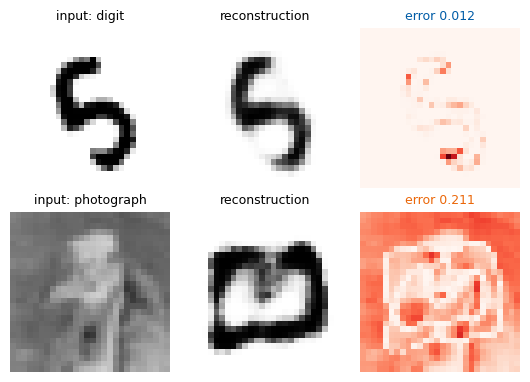

median error: digits 0.0121 | photographs 0.2112


In [30]:
kd = np.argsort(err_in)[len(err_in) // 2]; ko = np.argsort(err_ood)[len(err_ood) // 2]   # median cases
with torch.no_grad():
    rd_ = dec16(enc16(Xte_t[kd:kd + 1]))[0].numpy(); ro_ = dec16(enc16(ood[ko:ko + 1]))[0].numpy()
xd_, xo_ = Xte[kd], ood[ko].numpy()
fig, axs = plt.subplots(2, 3, figsize=(5.4, 3.9))
vmax = max(((xd_ - rd_) ** 2).max(), ((xo_ - ro_) ** 2).max())
for r, (xin, xr, e, lab) in enumerate([(xd_, rd_, err_in[kd], "digit"), (xo_, ro_, err_ood[ko], "photograph")]):
    for c, (im, cm) in enumerate([(xin, "gray_r"), (xr, "gray_r"), ((xin - xr) ** 2, "Reds")]):
        axs[r, c].imshow(im.reshape(28, 28), cmap=cm, vmin=0, vmax=(vmax if c == 2 else 1)); axs[r, c].axis("off")
    axs[r, 0].set_title(f"input: {lab}", fontsize=9); axs[r, 1].set_title("reconstruction", fontsize=9)
    axs[r, 2].set_title(f"error {e:.3f}", fontsize=9, color=(orange if r else blue))
plt.tight_layout(); plt.savefig(f"{OUT}/gen_anomaly_idea.png", dpi=170, bbox_inches="tight"); plt.show()
nums["idea_err_digit"] = float(err_in[kd]); nums["idea_err_photo"] = float(err_ood[ko])
print("median error: digits", round(float(np.median(err_in)), 4), "| photographs", round(float(np.median(err_ood)), 4))


## 7. Blood cells without labels

The BloodMNIST images of Lecture 4, part of MedMNIST ([Yang et al., *Sci. Data* **10**, 41 (2023)](https://doi.org/10.1038/s41597-022-01721-8)), are microscope images of eight types of **normal** blood cells from the data set of [Acevedo et al., *Data in Brief* **30**, 105474 (2020)](https://doi.org/10.1016/j.dib.2020.105474): cells from people without infection and without haematologic or oncologic disease. One sample is a $28\times28$ colour image (three channels with values 0 to 255) of a single cell, labelled with its type: basophil, eosinophil, erythroblast, immature granulocyte, lymphocyte, monocyte, neutrophil or platelet. Of the 17 092 images, 11 959 are for training, 1712 for validation and 3421 for testing; examples of every type are shown further below. We use the test images for the maps and the training images for the autoencoders. The cell types are used only to colour the points and to score the clusters.

We look at three views: PCA of the pixels, t-SNE of the pixels, and t-SNE of the 16 latent numbers of a convolutional autoencoder trained on the images alone. k-means with eight clusters is then compared with the cell types. The scores are low for both inputs: ARI 0.328 on the 50 PCA components of the pixels and 0.336 on the latent space. The autoencoder trains in about two minutes (125 s).

In [31]:
import urllib.request
bpath = "data/bloodmnist.npz"
if not os.path.exists(bpath):
    os.makedirs("data", exist_ok=True)
    urllib.request.urlretrieve("https://zenodo.org/records/10519652/files/bloodmnist.npz?download=1", bpath)
bd = np.load(bpath)
bnames = ["basophil", "eosinophil", "erythroblast", "immature gran.", "lymphocyte", "monocyte", "neutrophil", "platelet"]
Bte = bd["test_images"].astype(np.float32) / 255; byte = bd["test_labels"].ravel()
Btr = bd["train_images"].astype(np.float32) / 255; bytr = bd["train_labels"].ravel()
Bte_t = torch.tensor(Bte).permute(0, 3, 1, 2); Btr_t = torch.tensor(Btr).permute(0, 3, 1, 2)

class ConvAE3(nn.Module):                       # convolutional autoencoder for 3-channel 28x28 images
    def __init__(self, d=16):
        super().__init__()
        self.enc = nn.Sequential(nn.Conv2d(3, 32, 3, 2, 1), nn.ReLU(), nn.Conv2d(32, 64, 3, 2, 1), nn.ReLU(),
                                 nn.Flatten(), nn.Linear(64 * 7 * 7, 128), nn.ReLU(), nn.Linear(128, d))
        self.dec = nn.Sequential(nn.Linear(d, 128), nn.ReLU(), nn.Linear(128, 64 * 7 * 7), nn.ReLU(), nn.Unflatten(1, (64, 7, 7)),
                                 nn.ConvTranspose2d(64, 32, 3, 2, 1, output_padding=1), nn.ReLU(),
                                 nn.ConvTranspose2d(32, 3, 3, 2, 1, output_padding=1), nn.Sigmoid())
    def forward(self, x): return self.dec(self.enc(x))
def train_cae3(X, epochs=20, seed_=4):
    st = torch.get_rng_state(); torch.manual_seed(seed_)
    m = ConvAE3(); o = torch.optim.Adam(m.parameters(), 1e-3)
    for ep in range(epochs):
        perm = torch.randperm(len(X))
        for i in range(0, len(perm), 128):
            b = X[perm[i:i + 128]]; loss = ((m(b) - b) ** 2).mean(); o.zero_grad(); loss.backward(); o.step()
    torch.set_rng_state(st); m.eval(); return m

t0b = time.time(); bae = train_cae3(Btr_t)
with torch.no_grad(): BL = bae.enc(Bte_t).numpy()
BZ = PCA(50, random_state=0).fit_transform(Bte.reshape(len(Bte), -1))
BEp = TSNE(2, perplexity=30, init="pca", random_state=0).fit_transform(BZ)
BEl = TSNE(2, perplexity=30, init="pca", random_state=0).fit_transform(BL)
nums["blood_ari_pca50"] = float(adjusted_rand_score(byte, KMeans(8, n_init=10, random_state=0).fit(BZ).labels_))
nums["blood_ari_latent"] = float(adjusted_rand_score(byte, KMeans(8, n_init=10, random_state=0).fit(BL).labels_))
fig, axs = plt.subplots(1, 3, figsize=(13, 3.9))
for a, P2, t in zip(axs, [BZ[:, :2], BEp, BEl], ["PCA of the pixels", "t-SNE of the pixels", "t-SNE of the autoencoder latent space"]):
    for c in range(8):
        m = byte == c; a.scatter(P2[m, 0], P2[m, 1], s=3, color=cmap(c), label=bnames[c])
    a.set_title(t, fontsize=11); a.set_xticks([]); a.set_yticks([]); clean(a)
axs[2].legend(markerscale=4, fontsize=8, frameon=False, loc="upper right", bbox_to_anchor=(1.45, 1))
plt.tight_layout(); plt.savefig(f"{OUT}/gen_blood_maps.png", dpi=170, bbox_inches="tight"); plt.show()
print(f"trained in {time.time() - t0b:.0f} s;", {k: round(nums[k], 3) for k in ["blood_ari_pca50", "blood_ari_latent"]})

trained in 125 s; {'blood_ari_pca50': 0.328, 'blood_ari_latent': 0.336}


/tmp/ipykernel_3991246/70409028.py:44: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.tight_layout(); plt.savefig(f"{OUT}/gen_blood_maps.png", dpi=170, bbox_inches="tight"); plt.show()


### t-SNE settings for the blood cells

The cell types barely separate on the t-SNE maps above, so we ask whether other settings help. We try perplexity 5, 30 and 100 with 2000 iterations, on three inputs: the 50 PCA components of the pixels, the 50 PCA components of standardised pixels, and the autoencoder latent space. Each map is measured in two ways: by the accuracy of a 10-nearest-neighbour vote (5-fold cross-validation), which asks whether neighbours on the map share a cell type, and by the ARI of k-means with eight clusters.

No setting helps. On every input the neighbour vote is more accurate on the input itself than on any of its t-SNE maps (for the pixels 0.713 before t-SNE, 0.645 to 0.660 after), and the k-means ARI stays between 0.25 and 0.32. The neighbour vote is still far above chance, 0.195, the fraction of the most frequent type: neighbouring cells often share a type, but the types do not form separate groups.

In [ ]:
# Do other t-SNE settings group the cell types better? Perplexity 5, 30, 100 (2000 iterations), on three inputs.
# Measured on each 2D map: accuracy of a 10-nearest-neighbour vote (5-fold cross-validation) and k-means ARI.
import inspect
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import StandardScaler
knn10 = lambda F: float(cross_val_score(KNeighborsClassifier(10), F, byte, cv=5).mean())
ari8 = lambda F: float(adjusted_rand_score(byte, KMeans(8, n_init=10, random_state=0).fit_predict(F)))
it_kw = {"max_iter" if "max_iter" in inspect.signature(TSNE).parameters else "n_iter": 2000}
inputs = {"pixels, 50 PCA components": BZ,
          "standardised pixels, 50 PCA components": PCA(50, random_state=0).fit_transform(StandardScaler().fit_transform(Bte.reshape(len(Bte), -1))),
          "autoencoder latent space (16)": BL}
perps = [5, 30, 100]; sweep = {}
for name, Fin in inputs.items():
    sweep[name] = {"input": (knn10(Fin), ari8(Fin))}
    for perp in perps:
        E = TSNE(2, perplexity=perp, init="pca", random_state=0, **it_kw).fit_transform(Fin)
        sweep[name][perp] = (knn10(E), ari8(E))
    print(name, {k: tuple(round(x, 3) for x in v) for k, v in sweep[name].items()})
nums["blood_tsne_sweep"] = {n: {str(k): v for k, v in d.items()} for n, d in sweep.items()}
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
for j, (name, d) in enumerate(sweep.items()):
    for a, m in zip(axs, [0, 1]):
        a.plot(perps, [d[p][m] for p in perps], "o-", color=cmap(j), lw=2, label=name)
        a.axhline(d["input"][m], color=cmap(j), ls=":", lw=1.2)
for a, t in zip(axs, ["10-nearest-neighbour accuracy on the map", "k-means ARI on the map"]):
    a.set_xscale("log"); a.set_xticks(perps); a.set_xticklabels(perps, fontsize=12); a.tick_params(labelsize=12)
    a.set_xlabel("perplexity", fontsize=13); a.set_title(t, fontsize=13); clean(a)
axs[0].set_ylim(0.5, 0.8); axs[1].set_ylim(0.2, 0.4)
axs[0].legend(frameon=False, fontsize=10, loc="lower left")
plt.tight_layout(); plt.savefig(f"{OUT}/gen_blood_tsne_sweep.png", dpi=170, bbox_inches="tight"); plt.show()
print("dotted lines: the same measure on the input itself, before t-SNE; chance level of the neighbour vote:",
      round(float(np.bincount(byte).max() / len(byte)), 3))
nums["blood_majority_frac"] = float(np.bincount(byte).max() / len(byte))


pixels, 50 PCA components {'input': (0.713, 0.328), 5: (0.645, 0.255), 30: (0.66, 0.308), 100: (0.648, 0.31)}


standardised pixels, 50 PCA components {'input': (0.652, 0.255), 5: (0.582, 0.251), 30: (0.607, 0.302), 100: (0.607, 0.304)}


autoencoder latent space (16) {'input': (0.697, 0.336), 5: (0.644, 0.281), 30: (0.667, 0.316), 100: (0.657, 0.317)}


dotted lines: the same measure on the input itself, before t-SNE; chance level of the neighbour vote: 0.195


/tmp/ipykernel_3991246/2411723519.py:31: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.tight_layout(); plt.savefig(f"{OUT}/gen_blood_tsne_sweep.png", dpi=170, bbox_inches="tight"); plt.show()


### DBSCAN on the blood-cell map

The groups in the t-SNE maps have irregular shapes and touch each other, which k-means handles badly. DBSCAN follows dense regions instead. We run it on the t-SNE map of the pixels with at least ten points and radii $\varepsilon$ from 1.5 to 3.0; the cell types are used only to score the result, on the points that DBSCAN does not call noise.

The output shows no good compromise. With the radius 1.5, 91% of the cells are noise. With 2.0 there are 67 small clusters, 35% noise, and ARI 0.33 on the clustered cells. With 2.5 and 3.0 the map falls apart into a few large clusters with ARI 0.00. The density on the map does not follow the cell types. The figure after that shows three test images of each of the eight types; the test set holds between 243 and 666 images per type.

eps 1.5: 23 clusters, 91.0% noise, ARI on the clustered cells 0.22
eps 2.0: 67 clusters, 35.0% noise, ARI on the clustered cells 0.33
eps 2.5: 12 clusters, 7.2% noise, ARI on the clustered cells -0.00
eps 3.0: 6 clusters, 2.6% noise, ARI on the clustered cells 0.00


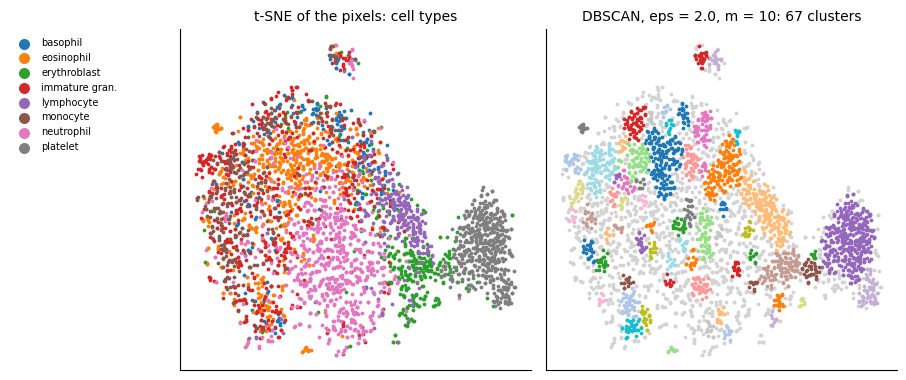

In [32]:
from sklearn.cluster import DBSCAN
rows = []
for eps in [1.5, 2.0, 2.5, 3.0]:
    lab = DBSCAN(eps=eps, min_samples=10).fit(BEp).labels_
    ncl = len(set(lab)) - (1 if -1 in lab else 0); noise = float((lab == -1).mean())
    ok = lab != -1
    rows.append((eps, ncl, noise, float(adjusted_rand_score(byte[ok], lab[ok]))))
    print(f"eps {eps}: {ncl} clusters, {noise:.1%} noise, ARI on the clustered cells {rows[-1][3]:.2f}")
nums["blood_dbscan"] = [list(r) for r in rows]
eps_show = 2.0; labd = DBSCAN(eps=eps_show, min_samples=10).fit(BEp).labels_
fig, axs = plt.subplots(1, 2, figsize=(9, 3.9))
for c in range(8):
    m = byte == c; axs[0].scatter(BEp[m, 0], BEp[m, 1], s=3, color=cmap(c), label=bnames[c])
axs[0].set_title("t-SNE of the pixels: cell types", fontsize=10)
cm20 = plt.get_cmap("tab20")
axs[1].scatter(BEp[labd == -1, 0], BEp[labd == -1, 1], s=3, color="lightgrey", label="noise")
for j, c in enumerate(sorted(set(labd) - {-1})):
    m = labd == c; axs[1].scatter(BEp[m, 0], BEp[m, 1], s=3, color=cm20(j % 20))
axs[1].set_title(f"DBSCAN, eps = {eps_show}, m = 10: {len(set(labd) - {-1})} clusters", fontsize=10)
for a in axs: a.set_xticks([]); a.set_yticks([]); clean(a)
axs[0].legend(markerscale=4, fontsize=7, frameon=False, loc="upper left", bbox_to_anchor=(-0.5, 1))
plt.tight_layout(); plt.savefig(f"{OUT}/gen_blood_dbscan.png", dpi=170, bbox_inches="tight"); plt.show()


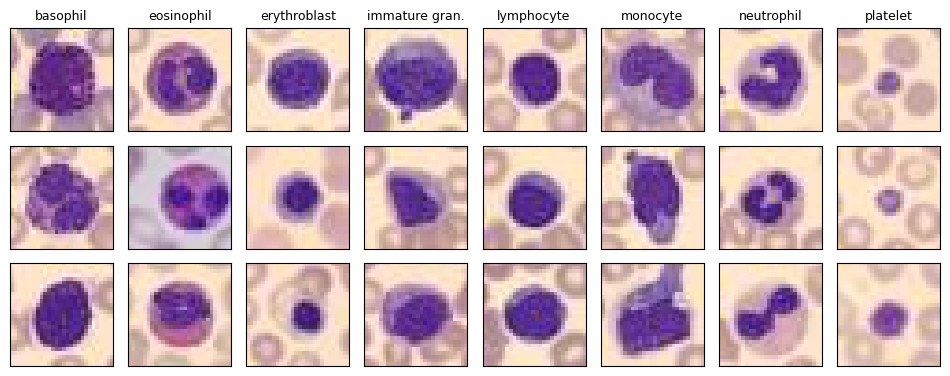

test images per type: [244 624 311 579 243 284 666 470] | train: 11959 | test: 3421


In [33]:
# examples of the eight cell types (the first three test images of each type)
fig, axs = plt.subplots(3, 8, figsize=(9.6, 3.9))
for c in range(8):
    for r, t in enumerate(np.flatnonzero(byte == c)[:3]):
        axs[r, c].imshow(Bte[t]); axs[r, c].set_xticks([]); axs[r, c].set_yticks([])
    axs[0, c].set_title(bnames[c], fontsize=9)
plt.tight_layout(); plt.savefig(f"{OUT}/gen_blood_examples28.png", dpi=170, bbox_inches="tight"); plt.show()
print("test images per type:", np.bincount(byte), "| train:", len(bytr), "| test:", len(byte))


### Anomaly detection on blood cells

In a clinic, an autoencoder trained on normal cells could flag cells that look unlike anything it has seen, for a pathologist to review. BloodMNIST contains only normal cells, so we imitate the task: we train the convolutional autoencoder on seven cell types and treat the eighth, never seen, as the anomaly. We repeat this for each of the eight types and report the AUC, the probability that a cell of the hidden type gets a larger reconstruction error than a cell of the trained types (0.5 is chance, 1 is perfect).

The results are mixed. Hidden neutrophils are found best (AUC 0.807), eosinophils next (0.644), and basophils, immature granulocytes, lymphocytes and monocytes lie between 0.52 and 0.59, close to chance. Erythroblasts and platelets even get smaller errors than the trained types (AUC 0.445 and 0.335), so a small reconstruction error does not mean that a cell type is familiar to the autoencoder.

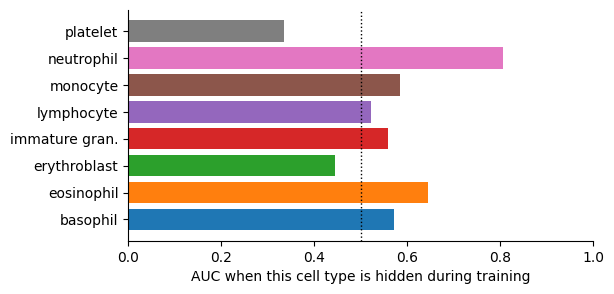

8 trainings in 167 s; {'basophil': np.float64(0.571), 'eosinophil': np.float64(0.644), 'erythroblast': np.float64(0.445), 'immature gran.': np.float64(0.559), 'lymphocyte': np.float64(0.522), 'monocyte': np.float64(0.585), 'neutrophil': np.float64(0.807), 'platelet': np.float64(0.335)}


In [34]:
from sklearn.metrics import roc_auc_score
aucs = []; t0b = time.time()
for hidden in range(8):
    m = train_cae3(Btr_t[torch.tensor(bytr != hidden)], epochs=10, seed_=10 + hidden)
    with torch.no_grad(): err = ((m(Bte_t) - Bte_t) ** 2).mean((1, 2, 3)).numpy()
    aucs.append(float(roc_auc_score(byte == hidden, err)))
nums["blood_anomaly_auc"] = [round(a, 3) for a in aucs]
fig, ax = plt.subplots(figsize=(6, 3.0))
ax.barh(range(8), aucs, color=[cmap(c) for c in range(8)]); ax.axvline(0.5, color="k", ls=":", lw=1)
ax.set_yticks(range(8)); ax.set_yticklabels(bnames); ax.set_xlim(0, 1); ax.set_xlabel("AUC when this cell type is hidden during training"); clean(ax)
plt.savefig(f"{OUT}/gen_blood_anomaly_auc.png", dpi=170, bbox_inches="tight"); plt.show()
print(f"8 trainings in {time.time() - t0b:.0f} s;", dict(zip(bnames, np.round(aucs, 3))))

### Exercise

Use the features of the CNN trained on the labelled cells in Lecture 4 instead of the autoencoder latent space. Do the clusters match the cell types better? Why is that not a fair comparison for unsupervised learning?

## 8. The 2D Ising model without labels

In Lecture 4 a CNN found the critical temperature $T_c$, but only because we gave it labels (ordered or disordered) far from the transition. Here the methods receive **only the spin configurations**.

The configurations are sampled with checkerboard Metropolis updates on a $32\times32$ lattice with the coupling $J$ set to 1, no external field and periodic boundaries, at 26 temperatures between 1 and 3.5. At each temperature we run four chains, equilibrate them for 800 sweeps and then store 25 configurations 10 sweeps apart, 2600 configurations in all. Chains below $T_c$ start from a fully ordered state, chains above it from a random one. One sample is a configuration of $32\times32$ spins, each $\pm1$, flattened to a vector of 1024 numbers; its temperature is known but is used only to colour and evaluate the results.

In [35]:
# ---------------- Ising: PCA and autoencoder anomaly detection ----------------
L = 32; Ts = np.round(np.linspace(1.0, 3.5, 26), 2); Tc = 2 / np.log(1 + np.sqrt(2))
mask = (np.add.outer(np.arange(L), np.arange(L)) % 2).astype(bool)
def sweep(s, T):
    for msk in (mask, ~mask):
        nb = np.roll(s, 1, 0) + np.roll(s, -1, 0) + np.roll(s, 1, 1) + np.roll(s, -1, 1)
        dE = 2 * s * nb; acc = (dE <= 0) | (rng.random(s.shape) < np.exp(-dE / T)); s[msk & acc] *= -1
    return s
confs, temps = [], []
for T in Ts:
    for chain in range(4):
        s = rng.choice([-1, 1], (L, L)) if T > Tc else np.ones((L, L), int) * rng.choice([-1, 1])
        for _ in range(800): s = sweep(s, T)
        for k in range(25):
            for _ in range(10): s = sweep(s, T)
            confs.append(s.copy().ravel()); temps.append(T)
C = np.array(confs, float); temps = np.array(temps)
nums["ising_n_configs"] = int(len(C)); nums["ising_L"] = L
log("Ising sampling done")

[3508.0s] Ising sampling done


### PCA of spin configurations

PCA receives the spins, never the temperature, which is used only to colour the points. Is its first component the magnetisation
$$M=\frac1N\sum_i s_i\ ? \tag{27}$$
(Wang, Phys. Rev. B 94, 195105, 2016.) The first component carries 48.4% of the variance, and its correlation with $M$ over the 2600 configurations is 0.9999999. The figure, saved for the slides, compares $\langle|\mathrm{PC\,1}|\rangle$, divided by $\sqrt N$, with $\langle|M|\rangle$ as functions of temperature.

In [36]:
pi = PCA(2).fit(C); P = pi.transform(C)
nums["ising_pc1_var"] = float(pi.explained_variance_ratio_[0])
M = C.mean(1)
nums["ising_corr_pc1_M"] = float(np.corrcoef(P[:, 0], M)[0, 1])
fig, axs = plt.subplots(1, 2, figsize=(9.4, 3.7))
sc = axs[0].scatter(P[:, 0], P[:, 1], c=temps, cmap="coolwarm", s=4)
axs[0].set_xlabel("PC 1"); axs[0].set_ylabel("PC 2"); axs[0].set_title("PCA of spin configurations", fontsize=11)
cb = plt.colorbar(sc, ax=axs[0]); cb.set_label("temperature $T$ (only for colour)")
pm = [np.abs(P[temps == T, 0]).mean() / np.sqrt(L * L) for T in Ts]
mm = [np.abs(M[temps == T]).mean() for T in Ts]
axs[1].plot(Ts, pm, "o-", color=orange, label=r"$\langle|\mathrm{PC\,1}|\rangle/\sqrt{N}$")
axs[1].plot(Ts, mm, "s--", color=blue, ms=4, label=r"$\langle|M|\rangle$")
axs[1].axvline(Tc, color="k", ls=":", lw=1); axs[1].text(Tc + 0.03, 0.05, "$T_c$")
axs[1].set_xlabel("$T$"); axs[1].legend(frameon=False); axs[1].set_title("first component = magnetisation", fontsize=11)
for a in axs: clean(a)
plt.tight_layout(); plt.savefig(f"{OUT}/gen_ising_pca.png", dpi=170, bbox_inches="tight"); plt.close()
log("Ising PCA done")
print({k: nums[k] for k in ['ising_pc1_var', 'ising_corr_pc1_M']})

[3508.6s] Ising PCA done


{'ising_pc1_var': 0.48406358231533997, 'ising_corr_pc1_M': 0.9999998663352911}


### The first principal component

Why the first component is the magnetisation can be seen directly. Each configuration is a vector $\mathbf s$ of $N$ spins $\pm1$, here 1024. Below $T_c$ the configurations are almost all up or almost all down, so the largest variance of the data lies along the uniform direction
$$\boldsymbol\lambda_1\approx\frac{(1,\dots,1)}{\sqrt N}. \tag{28}$$
Projecting on it gives
$$w^{(1)}=\boldsymbol\lambda_1^{\top}(\mathbf s-\bar{\mathbf s})\approx\frac1{\sqrt N}\sum_i s_i=\sqrt N\,M, \tag{29}$$
since the mean $\bar{\mathbf s}$ is close to zero when up and down are equally frequent. So the first component is the magnetisation of equation (27).

We check that $\boldsymbol\lambda_1$ is indeed uniform by plotting $\sqrt N\,\lambda_{1i}$ on the lattice, which would be 1 everywhere for an exactly uniform vector. The 1024 entries have mean 1.0 and a relative spread of 0.0096.

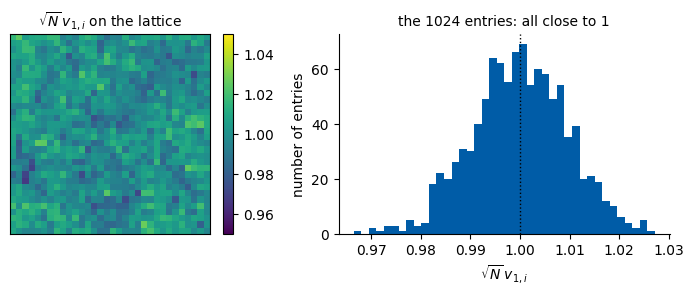

relative spread of the entries: 0.0096 | mean of sqrt(N) v_1i: 1.0


In [37]:
v1 = pi.components_[0] * np.sign(pi.components_[0].mean())
w = v1 * np.sqrt(L * L)                                       # sqrt(N) * entries: 1 for an exactly uniform vector
nums["ising_v1_rel_spread"] = float(w.std() / w.mean())
nums["ising_v1_mean_times_sqrtN"] = float(w.mean())
fig, axs = plt.subplots(1, 2, figsize=(7.4, 3.0), gridspec_kw=dict(width_ratios=[1, 1.2]))
im = axs[0].imshow(w.reshape(L, L), cmap="viridis", vmin=0.95, vmax=1.05)
plt.colorbar(im, ax=axs[0], fraction=0.046); axs[0].set_xticks([]); axs[0].set_yticks([])
axs[0].set_title(r"$\sqrt{N}\,v_{1,i}$ on the lattice", fontsize=10)
axs[1].hist(w, bins=40, color=blue); axs[1].axvline(1, color="k", ls=":", lw=1)
axs[1].set_xlabel(r"$\sqrt{N}\,v_{1,i}$"); axs[1].set_ylabel("number of entries"); axs[1].set_title("the 1024 entries: all close to 1", fontsize=10); clean(axs[1])
plt.tight_layout(); plt.savefig(f"{OUT}/gen_ising_v1.png", dpi=170, bbox_inches="tight"); plt.show()
print("relative spread of the entries:", round(nums["ising_v1_rel_spread"], 4), "| mean of sqrt(N) v_1i:", round(nums["ising_v1_mean_times_sqrtN"], 4))

### Autoencoder on ordered configurations

We train an autoencoder only on ordered configurations (temperatures up to 1.6), the "normal" data, and measure its reconstruction error at every temperature. Where does the error grow fastest? (Kottmann et al., Phys. Rev. Lett. 125, 170603, 2020, used this idea for quantum phases.) The steepest rise of the error is at the temperature 2.3, the grid temperature closest to the exact critical temperature
$$T_c=\frac{2}{\ln\big(1+\sqrt2\big)}\approx2.269 ; \tag{30}$$
the figure is saved for the slides.

In [38]:
# autoencoder trained only on ordered configurations (T <= 1.6)
class AE(nn.Module):
    def __init__(s, n=L * L, lat=8):
        super().__init__()
        s.e = nn.Sequential(nn.Linear(n, 128), nn.ReLU(), nn.Linear(128, lat))
        s.d = nn.Sequential(nn.Linear(lat, 128), nn.ReLU(), nn.Linear(128, n), nn.Tanh())
    def forward(s, x): return s.d(s.e(x))
ae = AE(); opt = torch.optim.Adam(ae.parameters(), 1e-3)
Ct = torch.tensor(C, dtype=torch.float32); tr = torch.tensor(temps <= 1.6)
Xn = Ct[tr]
for ep in range(300):
    perm = torch.randperm(len(Xn))
    for i in range(0, len(Xn), 64):
        b = Xn[perm[i:i + 64]]; loss = ((ae(b) - b) ** 2).mean(); opt.zero_grad(); loss.backward(); opt.step()
with torch.no_grad(): err = ((ae(Ct) - Ct) ** 2).mean(1).numpy()
em = np.array([err[temps == T].mean() for T in Ts]); es = np.array([err[temps == T].std() for T in Ts])
d = np.gradient(em, Ts); nums["ising_ae_max_slope_T"] = float(Ts[np.argmax(d)])
fig, ax = plt.subplots(figsize=(5.6, 3.4))
ax.axvspan(Ts[0], 1.6, color=blue, alpha=0.15, label="training data (ordered)")
ax.errorbar(Ts, em, yerr=es, fmt="o-", color=orange, ms=4, capsize=2, label="reconstruction error")
ax.axvline(Tc, color="k", ls=":", lw=1); ax.text(Tc + 0.03, em.max() * 0.05, "$T_c$")
ax.set_xlabel("$T$"); ax.set_ylabel("mean squared error"); ax.legend(frameon=False, loc="upper left"); clean(ax)
plt.savefig(f"{OUT}/gen_ising_ae_anomaly.png", dpi=170, bbox_inches="tight"); plt.close()
log("Ising AE done")
print('steepest rise of the error at T =', nums['ising_ae_max_slope_T'])

[3516.5s] Ising AE done


steepest rise of the error at T = 2.3


For the architecture diagram on the slides we show one ordered training configuration (temperature 1.0) and its reconstruction.

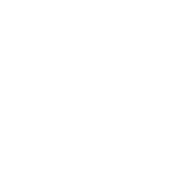

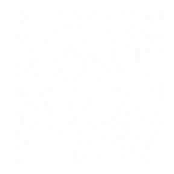

temperature of this configuration: 1.0


In [39]:
with torch.no_grad():
    s_in = Ct[0]; s_out = ae(Ct[:1])[0]
for arr, name in [(s_in.numpy(), "gen_ising_ae_in.png"), (s_out.numpy(), "gen_ising_ae_out.png")]:
    plt.figure(figsize=(2, 2)); plt.imshow(arr.reshape(L, L), cmap="gray", vmin=-1, vmax=1, interpolation="nearest"); plt.axis("off")
    plt.savefig(f"{OUT}/{name}", dpi=170, bbox_inches="tight", pad_inches=0.02); plt.show()
print("temperature of this configuration:", temps[0])

### Exercise

Train the autoencoder on disordered configurations (temperatures of 3 and above) instead. Does the reconstruction error still point to $T_c$?

## 9. Tabular data

### Credit-card fraud

The same tools work on any table of numbers. The data are 284 807 card transactions by European cardholders in two days of September 2013, 492 of them fraudulent (0.17%) ([Dal Pozzolo, Caelen, Johnson and Bontempi, IEEE Symposium Series on Computational Intelligence, 159 (2015)](https://doi.org/10.1109/SSCI.2015.33); from [OpenML, data set 1597](https://www.openml.org/d/1597), 150 MB, downloaded once). For confidentiality the original features are not given: `V1`–`V28` are already **principal components** of them, and only `Amount` (in euros) and `Time` (seconds since the first transaction) are original. One sample is one transaction with these 30 numbers and the label `Class`, 1 for fraud and 0 otherwise. We use `V1`–`V28` and the logarithm of the amount shifted by one, 29 columns in all (equation (31) below), and drop `Time`.

The labels exist, but we use them only to *score* the methods, as if fraud had never been seen. We first project the data to 2D with PCA to look at them. We then train an autoencoder only on the normal transactions of the training part (80% of the data) and use its reconstruction error as the anomaly score on the test part (20%). As a simple baseline we score each transaction by its distance from the mean of the normal ones.

The table as the autoencoder sees it, as drawn on the slides for the first five transactions, has one row per transaction,
$$\mathbf x_i=\big(V_1,\dots,V_{28},\ln(1+A)\big), \tag{31}$$
with $A$ the amount; `Class` is used only to evaluate.

In [ ]:
# the first five rows of the table as the autoencoder sees them: x_i = (V1, ..., V28, log(1 + Amount)); Class only to evaluate
fpath = "data/creditcard/creditcard.arff"
rows_ = []
with open(fpath) as f:
    for line in f:
        if line.startswith("@") or not line.strip(): continue
        rows_.append(line.strip().replace("'", "").split(","))
        if len(rows_) == 5: break
A5 = np.array(rows_, dtype=np.float64)
for r in A5:
    print(f"V1 {r[1]:6.2f}  V2 {r[2]:6.2f}  ...  V28 {r[28]:6.2f}  log(1+Amount) {np.log1p(r[29]):5.2f}  Class {int(r[30])}")


V1  -1.36  V2  -0.07  ...  V28  -0.02  log(1+Amount)  5.01  Class 0
V1   1.19  V2   0.27  ...  V28   0.01  log(1+Amount)  1.31  Class 0
V1  -1.36  V2  -1.34  ...  V28  -0.06  log(1+Amount)  5.94  Class 0
V1  -0.97  V2  -0.19  ...  V28   0.06  log(1+Amount)  4.82  Class 0
V1  -1.16  V2   0.88  ...  V28   0.22  log(1+Amount)  4.26  Class 0


284807 transactions, 492 frauds; test part: 56962 transactions, 98 frauds


flag the 0.5% largest errors: 62 of 98 frauds caught (63%); 21.8% of the flagged are fraud
flag the 1% largest errors: 73 of 98 frauds caught (74%); 12.8% of the flagged are fraud
flag the 2% largest errors: 76 of 98 frauds caught (78%); 6.7% of the flagged are fraud


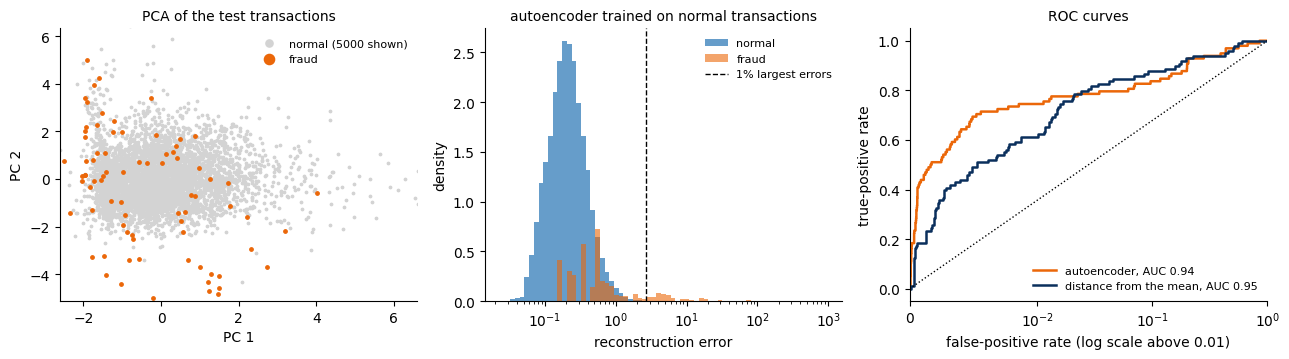

{'fraud_n': 284807, 'fraud_pos': 492, 'fraud_pca2_var': 0.099, 'fraud_ae_auc': 0.941, 'fraud_dist_auc': 0.949, 'fraud_top0.5_caught': 0.633, 'fraud_top0.5_precision': 0.218, 'fraud_top1_caught': 0.745, 'fraud_top1_precision': 0.128, 'fraud_top2_caught': 0.776, 'fraud_top2_precision': 0.067}


In [40]:
import urllib.request
fpath = "data/creditcard/creditcard.arff"
if not os.path.exists(fpath):
    os.makedirs("data/creditcard", exist_ok=True)
    urllib.request.urlretrieve("https://openml.org/data/v1/download/1673544/creditcard.arff", fpath)
rows_ = []
with open(fpath) as f:
    for line in f:
        if line.startswith("@") or not line.strip(): continue
        rows_.append(line.strip().replace("'", "").split(","))
A = np.array(rows_, dtype=np.float64); del rows_
Xf = A[:, 1:30].copy(); yf = A[:, 30].astype(int); Xf[:, 28] = np.log1p(Xf[:, 28])     # V1..V28, log(1 + Amount)
nums["fraud_n"] = int(len(yf)); nums["fraud_pos"] = int(yf.sum())
from sklearn.model_selection import train_test_split
Xf_tr, Xf_te, yf_tr, yf_te = train_test_split(Xf, yf, test_size=0.2, stratify=yf, random_state=0)
mu_f, sd_f = Xf_tr[yf_tr == 0].mean(0), Xf_tr[yf_tr == 0].std(0)                       # standardise with the normal training data
Zf_tr, Zf_te = (Xf_tr - mu_f) / sd_f, (Xf_te - mu_f) / sd_f
print(f"{len(yf)} transactions, {yf.sum()} frauds; test part: {len(yf_te)} transactions, {yf_te.sum()} frauds")

# PCA to 2D of the test part (all frauds and 5000 normal transactions)
rf_ = np.random.default_rng(11); sub = np.r_[rf_.choice(np.flatnonzero(yf_te == 0), 5000, replace=False), np.flatnonzero(yf_te == 1)]
pf = PCA(2).fit(Zf_tr[yf_tr == 0]); Pf = pf.transform(Zf_te[sub])
nums["fraud_pca2_var"] = float(pf.explained_variance_ratio_.sum())

# autoencoder 29 -> 16 -> 8 -> 16 -> 29, trained on normal transactions only
state = torch.get_rng_state(); torch.manual_seed(0)
encF = nn.Sequential(nn.Linear(29, 16), nn.ReLU(), nn.Linear(16, 8)); decF = nn.Sequential(nn.Linear(8, 16), nn.ReLU(), nn.Linear(16, 29))
optF = torch.optim.Adam(list(encF.parameters()) + list(decF.parameters()), 1e-3)
Nf = torch.tensor(Zf_tr[yf_tr == 0], dtype=torch.float32)
for ep in range(10):
    perm = torch.randperm(len(Nf))
    for i in range(0, len(Nf), 256):
        b = Nf[perm[i:i + 256]]; loss = ((decF(encF(b)) - b) ** 2).mean(); optF.zero_grad(); loss.backward(); optF.step()
torch.set_rng_state(state)
torch.save({"enc": encF.state_dict(), "dec": decF.state_dict()}, f"{RES}/fraud_ae.pt")
with torch.no_grad():
    Tf = torch.tensor(Zf_te, dtype=torch.float32); errF = ((decF(encF(Tf)) - Tf) ** 2).mean(1).numpy()
distF = (Zf_te ** 2).mean(1)                                                             # distance from the normal mean
nums["fraud_ae_auc"] = float(roc_auc_score(yf_te, errF)); nums["fraud_dist_auc"] = float(roc_auc_score(yf_te, distF))
for q in [0.5, 1, 2]:
    fl = errF > np.percentile(errF, 100 - q)
    nums[f"fraud_top{q}_caught"] = float(yf_te[fl].sum() / yf_te.sum()); nums[f"fraud_top{q}_precision"] = float(yf_te[fl].mean())
    print(f"flag the {q}% largest errors: {yf_te[fl].sum()} of {yf_te.sum()} frauds caught ({nums[f'fraud_top{q}_caught']:.0%}); {nums[f'fraud_top{q}_precision']:.1%} of the flagged are fraud")

fig, axs = plt.subplots(1, 3, figsize=(13, 3.7))
s0 = yf_te[sub] == 0
axs[0].scatter(Pf[s0, 0], Pf[s0, 1], s=3, color="lightgrey", label="normal (5000 shown)")
axs[0].scatter(Pf[~s0, 0], Pf[~s0, 1], s=6, color=orange, label="fraud")
axs[0].set_xlim(np.percentile(Pf[:, 0], [0.2, 99.8])); axs[0].set_ylim(np.percentile(Pf[:, 1], [0.2, 99.8]))
axs[0].set_title("PCA of the test transactions", fontsize=10); axs[0].set_xlabel("PC 1"); axs[0].set_ylabel("PC 2"); axs[0].legend(frameon=False, fontsize=8, markerscale=3)
bins = np.logspace(np.log10(errF.min()), np.log10(errF.max()), 70)
axs[1].hist(errF[yf_te == 0], bins=bins, density=True, alpha=0.6, color=blue, label="normal")
axs[1].hist(errF[yf_te == 1], bins=bins, density=True, alpha=0.6, color=orange, label="fraud")
axs[1].axvline(np.percentile(errF, 99), color="k", ls="--", lw=1, label="1% largest errors")
axs[1].set_xscale("log"); axs[1].set_xlabel("reconstruction error"); axs[1].set_ylabel("density"); axs[1].legend(frameon=False, fontsize=8)
axs[1].set_title("autoencoder trained on normal transactions", fontsize=10)
for sc, lab, col in [(errF, f"autoencoder, AUC {nums['fraud_ae_auc']:.2f}", orange), (distF, f"distance from the mean, AUC {nums['fraud_dist_auc']:.2f}", navy)]:
    fp_, tp_, _ = roc_curve(yf_te, sc); axs[2].plot(fp_, tp_, color=col, lw=1.8, label=lab)
axs[2].plot([0, 1], [0, 1], "k:", lw=1); axs[2].set_xscale("symlog", linthresh=0.01); axs[2].set_xlim(0, 1)
axs[2].set_xlabel("false-positive rate (log scale above 0.01)"); axs[2].set_ylabel("true-positive rate"); axs[2].set_title("ROC curves", fontsize=10); axs[2].legend(frameon=False, fontsize=8, loc="lower right")
for a in axs: clean(a)
plt.tight_layout(); plt.savefig(f"{OUT}/gen_fraud.png", dpi=170, bbox_inches="tight"); plt.show()
print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in nums.items() if k.startswith("fraud")})


Fraud is found well, but not by virtue of the autoencoder. The autoencoder reaches AUC 0.941, the plain distance from the mean 0.949. Flagging the 1% of test transactions with the largest reconstruction errors catches 73 of the 98 frauds (74%), and 12.8% of the flagged transactions are fraud; flagging 0.5% catches 63% with 21.8% precision. In the PCA projection to 2D, which keeps only 9.9% of the variance, part of the frauds lie at the edge of the normal cloud, but many sit inside it. The ROC curves, drawn with a logarithmic false-positive axis, show the autoencoder ahead at small false-positive rates and the distance from the mean ahead at larger ones.

### Exercise

The autoencoder is no better than the plain distance from the mean: the 29 columns are already principal components, so a fraud is mostly a transaction with unusually large values. Train the autoencoder with a smaller latent space (four latent numbers), or score with an isolation forest (`sklearn.ensemble.IsolationForest`). Does anything beat the baseline?

### Tumour gene expression

The UCI data set [*gene expression cancer RNA-Seq*](https://doi.org/10.24432/C5R88H) (University of California, Irvine, Machine Learning Repository, id 401, CC BY 4.0; S. Fiorini, 2016) is a random extraction from the pan-cancer ribonucleic acid sequencing (RNA-Seq, Illumina HiSeq) data of The Cancer Genome Atlas (TCGA): 801 tumour samples, each a vector of 20 531 gene-expression values. The gene names are anonymised (`gene_0`, ...). The values range from 0 to about 20.8, which looks like a logarithmic scale; the normalisation is not documented on the UCI page. There are five tumour types: breast invasive carcinoma (BRCA, 300 samples), kidney renal clear cell carcinoma (KIRC, 146), lung adenocarcinoma (LUAD, 141), prostate adenocarcinoma (PRAD, 136) and colon adenocarcinoma (COAD, 78). The type is used only to evaluate.

The question is the anomaly question once more: is a tumour type that was never seen in training recognised as unusual?

In [ ]:
# TCGA pan-cancer RNA-Seq (UCI data set 401): 801 tumour samples x 20 531 genes, five tumour types
import zipfile, tarfile, io, urllib.request
import pandas as pd
zpath = "data/rnaseq.zip"
if not os.path.exists(zpath):
    os.makedirs("data", exist_ok=True)
    urllib.request.urlretrieve("https://archive.ics.uci.edu/static/public/401/gene+expression+cancer+rna+seq.zip", zpath)
with zipfile.ZipFile(zpath) as z:
    tgz = io.BytesIO(z.read("TCGA-PANCAN-HiSeq-801x20531.tar.gz"))
with tarfile.open(fileobj=tgz) as t:
    G = pd.read_csv(t.extractfile("TCGA-PANCAN-HiSeq-801x20531/data.csv"), index_col=0)
    gy = pd.read_csv(t.extractfile("TCGA-PANCAN-HiSeq-801x20531/labels.csv"), index_col=0)["Class"].values
Gx = G.values.astype(np.float32); gtypes = ["BRCA", "KIRC", "LUAD", "PRAD", "COAD"]
print(G.shape, "| genes:", list(G.columns[:3]), "... | values from", Gx.min(), "to", round(float(Gx.max()), 1))
print({c: int((gy == c).sum()) for c in gtypes})
nums["rna_n"], nums["rna_genes"], nums["rna_max"] = int(Gx.shape[0]), int(Gx.shape[1]), float(Gx.max())
print(G.iloc[:5, [1, 2, 3, 20530]].round(2).assign(type=gy[:5]))            # the first rows, as drawn on the slide


(801, 20531) | genes: ['gene_0', 'gene_1', 'gene_2'] ... | values from 0.0 to 20.8
{'BRCA': 300, 'KIRC': 146, 'LUAD': 141, 'PRAD': 136, 'COAD': 78}
          gene_1  gene_2  gene_3  gene_20530  type
sample_0    2.02    3.27    5.48         0.0  PRAD
sample_1    0.59    1.59    7.59         0.0  LUAD
sample_2    3.51    4.33    6.88         0.0  PRAD
sample_3    3.66    4.51    6.66         0.0  PRAD
sample_4    2.66    2.82    6.54         0.0  BRCA


We train on four tumour types and treat the fifth, never seen in training, as the anomaly. The samples of the four known types are split 80/20 into training and test parts. We keep the 2000 genes with the largest variance, **computed on the training part only**, and standardise them with the training mean and standard deviation; using the test samples here would leak information. An autoencoder $2000\to256\to32\to256\to2000$ is trained on the training part, and the score $a(\mathbf x)$ is the mean squared reconstruction error over the 2000 genes. The baseline is the reconstruction error of PCA with the same 32 components. Each of the five types is held out in turn.

Both scores find the unseen type almost perfectly, with AUC between 0.960 and 0.999. PCA is as good as the autoencoder or slightly better for every held-out type, for instance 0.982 against 0.960 for LUAD: with a few hundred samples the linear model is hard to beat.

In [ ]:
# anomaly = a tumour type never seen in training; repeated with each of the five types held out
from sklearn.metrics import roc_auc_score
def rna_split(held, seed=0):
    r = np.random.default_rng(seed)
    known = np.flatnonzero(gy != held); r.shuffle(known)
    ntr = int(0.8 * len(known)); tr, te_norm = known[:ntr], known[ntr:]
    return tr, te_norm, np.flatnonzero(gy == held)
def rna_scores(held, n_genes=2000, d=32, epochs=300, seed=0):
    tr, te_n, te_a = rna_split(held, seed)
    var = Gx[tr].var(0); genes = np.argsort(var)[::-1][:n_genes]          # most variable genes, TRAINING part only
    mu, sd = Gx[tr][:, genes].mean(0), Gx[tr][:, genes].std(0) + 1e-6       # standardise with training statistics
    Z = lambda idx: (Gx[idx][:, genes] - mu) / sd
    Xtr_, Xn, Xa = map(lambda a: torch.tensor(a, dtype=torch.float32), (Z(tr), Z(te_n), Z(te_a)))
    torch.manual_seed(seed)
    enc = nn.Sequential(nn.Linear(n_genes, 256), nn.ReLU(), nn.Linear(256, d))
    dec = nn.Sequential(nn.Linear(d, 256), nn.ReLU(), nn.Linear(256, n_genes))
    opt = torch.optim.Adam(list(enc.parameters()) + list(dec.parameters()), 1e-3, weight_decay=1e-5)
    for ep in range(epochs):
        perm = torch.randperm(len(Xtr_))
        for i in range(0, len(perm), 64):
            b = Xtr_[perm[i:i + 64]]; loss = ((dec(enc(b)) - b) ** 2).mean(); opt.zero_grad(); loss.backward(); opt.step()
    with torch.no_grad():
        a_ae = lambda X: ((dec(enc(X)) - X) ** 2).mean(1).numpy()                 # a(x): mean squared error over the genes
        an, aa, atr = a_ae(Xn), a_ae(Xa), a_ae(Xtr_)
    pc = PCA(d, random_state=0).fit(Z(tr))                                       # baseline: PCA reconstruction, same d
    a_pca = lambda X: ((pc.inverse_transform(pc.transform(X)) - X) ** 2).mean(1)
    yt = np.r_[np.zeros(len(an)), np.ones(len(aa))]
    return dict(an=an, aa=aa, atr=atr, auc_ae=roc_auc_score(yt, np.r_[an, aa]),
                auc_pca=roc_auc_score(yt, np.r_[a_pca(Z(te_n)), a_pca(Z(te_a))]), n_tr=len(tr), n_n=len(te_n), n_a=len(te_a))
t0g = time.time(); rna = {h: rna_scores(h) for h in gtypes}
for h, r in rna.items():
    print(f"held out {h}: train {r['n_tr']}, test normal {r['n_n']}, test anomalies {r['n_a']}; AUC autoencoder {r['auc_ae']:.3f}, PCA {r['auc_pca']:.3f}")
print(f"{time.time() - t0g:.0f} s")
nums["rna_auc_ae"] = {h: float(r["auc_ae"]) for h, r in rna.items()}; nums["rna_auc_pca"] = {h: float(r["auc_pca"]) for h, r in rna.items()}


held out BRCA: train 400, test normal 101, test anomalies 300; AUC autoencoder 0.974, PCA 0.985
held out KIRC: train 524, test normal 131, test anomalies 146; AUC autoencoder 0.998, PCA 0.999
held out LUAD: train 528, test normal 132, test anomalies 141; AUC autoencoder 0.960, PCA 0.982
held out PRAD: train 532, test normal 133, test anomalies 136; AUC autoencoder 0.988, PCA 0.992
held out COAD: train 578, test normal 145, test anomalies 78; AUC autoencoder 0.988, PCA 0.991
176 s


The histogram for one held-out type, COAD, shows the threshold $\tau$ that flags 5% of the known test samples; 96% of the COAD samples lie above it. The bar chart gives the AUC of both scores for every held-out type.

In [ ]:
show = "COAD"; r = rna[show]
tau = np.percentile(r["an"], 95)                                   # 5% of the held-out known samples above tau
nums["rna_show"], nums["rna_frac_flagged"] = show, float((r["aa"] > tau).mean())
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw=dict(width_ratios=[1.25, 1]))
bins = np.linspace(0, max(r["an"].max(), r["aa"].max()) * 1.02, 40)
axs[0].hist(r["an"], bins=bins, color=blue, alpha=0.7, label="test samples of the 4 known types")
axs[0].hist(r["aa"], bins=bins, color=orange, alpha=0.7, label=f"{show}, never seen in training")
axs[0].axvline(tau, color="k", ls="--", lw=1.2, label=r"threshold $\tau$: 5% of known flagged")
axs[0].set_xlabel("anomaly score $a(\\mathbf{x})$", fontsize=12); axs[0].set_ylabel("number of samples", fontsize=12)
axs[0].legend(frameon=False, fontsize=10); axs[0].tick_params(labelsize=11)
x = np.arange(5); w = 0.38
axs[1].bar(x - w / 2, [rna[h]["auc_ae"] for h in gtypes], w, color=orange, label="autoencoder")
axs[1].bar(x + w / 2, [rna[h]["auc_pca"] for h in gtypes], w, color=blue, label="PCA reconstruction")
axs[1].set_xticks(x); axs[1].set_xticklabels(gtypes, fontsize=11); axs[1].set_ylim(0.5, 1.02)
axs[1].set_xlabel("tumour type held out of training", fontsize=12); axs[1].set_ylabel("AUC", fontsize=12)
axs[1].legend(frameon=False, fontsize=10, loc="lower right"); axs[1].tick_params(labelsize=11)
for a in axs: clean(a)
plt.tight_layout(); plt.savefig(f"{OUT}/gen_rnaseq_anomaly.png", dpi=170, bbox_inches="tight"); plt.show()
print(f"{show} held out: {nums['rna_frac_flagged']:.0%} of the {show} samples above tau")


COAD held out: 96% of the COAD samples above tau


/tmp/ipykernel_3945762/2062828859.py:18: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.tight_layout(); plt.savefig(f"{OUT}/gen_rnaseq_anomaly.png", dpi=170, bbox_inches="tight"); plt.show()


### Parameter counts

The other trained networks, of parts 4, 7 and 9, differ in size by three orders of magnitude. Untrained copies with the same layers give their layer tables with `torchinfo.summary`, and each total is checked against the sum of the parameter counts of the model. The deep convolutional autoencoder and the blood-cell autoencoder hold most of their parameters in the dense layers between the feature maps and the latent vector, as in equation (17); the fraud autoencoder, with 29 inputs, is tiny, while the RNA-Seq autoencoder has about a million parameters for a few hundred training samples, mostly in its first and last layer.

In [ ]:
# parameter counts of the other trained networks, from untrained copies with the same layers as in the training cells;
# building them and the dummy forward passes run inside fork_rng, so the global random generator is unchanged
from torchinfo import summary
with torch.random.fork_rng(devices=[]):
    models = {
        "deep convolutional autoencoder DeepConvAE(16), MNIST": (DeepConvAE(16), (2, 1, 28, 28)),
        "convolutional autoencoder ConvAE3(16), blood cells":   (ConvAE3(16), (2, 3, 28, 28)),
        "fraud autoencoder 29 -> 16 -> 8 -> 16 -> 29": (
            nn.Sequential(nn.Sequential(nn.Linear(29, 16), nn.ReLU(), nn.Linear(16, 8)),                  # as encF
                          nn.Sequential(nn.Linear(8, 16), nn.ReLU(), nn.Linear(16, 29))), (1, 29)),        # as decF
        "RNA-Seq autoencoder 2000 -> 256 -> 32 -> 256 -> 2000": (
            nn.Sequential(nn.Sequential(nn.Linear(2000, 256), nn.ReLU(), nn.Linear(256, 32)),             # as enc in rna_scores
                          nn.Sequential(nn.Linear(32, 256), nn.ReLU(), nn.Linear(256, 2000))), (1, 2000)),  # as dec in rna_scores
    }
    infos = {name: summary(m, input_size=size, verbose=0) for name, (m, size) in models.items()}
for name, (m, size) in models.items():
    info = infos[name]
    print(name); print(info)
    assert info.total_params == sum(p.numel() for p in m.parameters())
    assert info.trainable_params == sum(p.numel() for p in m.parameters() if p.requires_grad)
print({name: f"{infos[name].total_params:,}" for name in models})


deep convolutional autoencoder DeepConvAE(16), MNIST
Layer (type:depth-idx)                   Output Shape              Param #
DeepConvAE                               [2, 1, 28, 28]            --
├─Sequential: 1-1                        [2, 16]                   --
│    └─Conv2d: 2-1                       [2, 32, 28, 28]           320
│    └─BatchNorm2d: 2-2                  [2, 32, 28, 28]           64
│    └─ReLU: 2-3                         [2, 32, 28, 28]           --
│    └─Conv2d: 2-4                       [2, 64, 14, 14]           18,496
│    └─BatchNorm2d: 2-5                  [2, 64, 14, 14]           128
│    └─ReLU: 2-6                         [2, 64, 14, 14]           --
│    └─Conv2d: 2-7                       [2, 128, 7, 7]            73,856
│    └─BatchNorm2d: 2-8                  [2, 128, 7, 7]            256
│    └─ReLU: 2-9                         [2, 128, 7, 7]            --
│    └─Flatten: 2-10                     [2, 6272]                 --
│    └─Linear: 2-11  

## Collected numbers

The last cell saves and prints all numbers collected in `nums`, which are the numbers quoted on the slides.

In [41]:
json.dump(nums, open(f"{RES}/numbers_l5.json", "w"), indent=1)
print(json.dumps(nums, indent=1))

{
 "pca_toy_var": [
  0.945,
  0.055
 ],
 "mnist_pca_k_for_90": 87,
 "mnist_pca_frac_2_10_50": [
  0.168,
  0.488,
  0.825
 ],
 "mnist_pca_var2": 0.16800588418808224,
 "mnist_pca_var50": 0.824646863333519,
 "mnist_pca_var3": 0.22969677181175396,
 "ae2_test_mse": 0.04037584736943245,
 "ae16_test_mse": 0.013432577252388,
 "cae2_test_mse": 0.038878753781318665,
 "ae2_latent_kmeans_ari": 0.19675392273820874,
 "cae2_latent_kmeans_ari": 0.26933656768870523,
 "ae16_latent_kmeans_ari": 0.6685170808470863,
 "ae16_latent_kmeans_ari_direct": 0.28449900320658716,
 "dcae16_test_mse": 0.006785869132727385,
 "dcae16_pca2_var": 0.3131445348262787,
 "dcae16_kmeans_ari_direct": 0.5656113944646641,
 "dcae16_kmeans_ari_tsne": 0.9119372401125078,
 "anom_err_normal": 0.013625011779367924,
 "anom_err_seven": 0.018661338835954666,
 "anom_frac7_flagged": 0.1293774319066148,
 "anom_auc": 0.6779449272357929,
 "anom_top100_sevens": 24,
 "kmeans_ari_pca50": 0.3838588804938445,
 "kmeans_ari_tsne": 0.761565459467805